# Catastrophes, guerres, famines et récessions : les chocs font-ils tomber les partis autoritaires ?
*Fedi Jouili*

**Objectif.** Les modèles de Cox de `final_panel.ipynb` expliquent la durée de vie des partis autoritaires par leur origine, leur stratégie de gouvernance, leur idéologie, le niveau démocratique, le PIB par habitant et le conflit armé. Ce notebook teste si un **choc** subi par le pays l'année précédente change le risque qu'un parti perde le pouvoir : une catastrophe naturelle soudaine, un grand séisme, des morts au combat, une guerre entre États, une famine, un choc sur la production alimentaire ou une récession sévère.

Il reprend le protocole et les règles de `04_demographics.ipynb`, appliqués à la seule **Tâche B** (chute dans l'année, modèle de Cox time-varying) : un choc est un événement daté, pas une caractéristique du pays à l'arrivée au pouvoir. Les sept variables forment un seul bloc et une famille de correction de Holm distincte de celle du notebook 04, dont les résultats ne changent pas.

**Ce que ce notebook ne fait pas.** Il ne modifie aucun résultat existant : les données, modèles et exports de `final_panel.ipynb`, `03_ml_survival.ipynb` et `04_demographics.ipynb` sont lus, jamais réécrits, et le modèle du site n'est pas changé. Les définitions des variables et les règles de décision ont été fixées avant tout résultat (Sections 3 et 5).

**Précautions.** Un choc décrit ce qui arrive au pays, pas un choix du parti : aucune de ces variables ne deviendra un paramètre de la simulation du site. Les résultats décrivent des associations, pas des causes : une famine ou une guerre peut venir du régime lui-même.

## Plan du notebook
0. Configuration
1. Sources des données
2. Codes pays et États historiques
3. Construction des variables
4. Fusion avec le jeu time-varying, couverture et colinéarité
5. Règles de décision (fixées avant les résultats)
6. Modèles estimés sur l'échantillon commun (hazard ratios)
7. Validation croisée (prédiction)
8. Décision et modèle final
9. Conclusion et limites
10. Export des résultats
11. Références

## 0. Configuration

In [1]:
# ============================================================
# 0. Configuration et imports
# ============================================================
import hashlib
import json
import re
import sys
import time
import urllib.request
import warnings
import zipfile
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from lifelines import CoxPHFitter, CoxTimeVaryingFitter
from scipy import stats
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
ALPHA = 0.05
PENALIZER = 0.01          # même spécification que final_panel.ipynb, 03_ml_survival.ipynb et 04_demographics.ipynb
N_FOLDS, N_REPEATS, N_INNER = 5, 10, 3
MIN_FALLS = 120           # une variable doit laisser au moins 120 chutes (règle de 04_demographics.ipynb)
MIN_EPP = 10              # aucun modèle n'est estimé avec moins de 10 chutes par paramètre
CONCORDANCE_MIN = 0.8     # raccord des morts au combat PRIO / UCDP (Section 3.4)
QUAKE_MIN = 7.5           # grand séisme : NOAA recense tous les séismes de cette magnitude, avec ou sans dégâts
FOOD_DROP, RECESSION = -0.10, -0.05   # baisses sur un an : production alimentaire par habitant, PIB par habitant
YEARS = (1945, 2024)      # années de la table pays-année (un choc de l'année t sert à expliquer une chute en t + 1)

# Racine du projet : fonctionne que le notebook soit lancé depuis la racine ou depuis notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
assert (PROJECT_ROOT / "data").is_dir(), f"Racine du projet introuvable depuis {Path.cwd()}"
RAW, PROC = PROJECT_ROOT / "data" / "raw", PROJECT_ROOT / "data" / "processed"
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from site_export import write_json

## 1. Sources des données

| Variable | Source | Version | Fichier dans `data/raw/` | Citation | Conditions d'utilisation |
|---|---|---|---|---|---|
| D1 | EM-DAT, archive validée de la base (CRED, UCLouvain) | v2, publiée le 30 avril 2026 (événements de 1900 à 2024) | `260430_emdat_archive.xlsx` | Delforge et al. (2025) ; CRED / UCLouvain, EM-DAT | CC BY-NC-ND 4.0 : usage non commercial, **pas de diffusion de données modifiées** |
| D2 | NOAA NCEI, base des séismes significatifs (API HazEL) | consultation datée ci-dessous | `noaa_significant_earthquakes.csv` | NCEI/WDS, doi:10.7289/V5TD9V7K | aucune licence indiquée ; données du gouvernement des États-Unis ; citation demandée |
| D3 | PRIO Battle Deaths Dataset | 3.1 (1946-2008) | `PRIO_BattleDeaths_v3.1.xls` | Lacina & Gleditsch (2005) ; PRIO (2009) | aucune licence indiquée |
| D3 | UCDP Battle-Related Deaths Dataset, version par conflit ; table de correspondance des identifiants de conflit | 26.1 (1989-2025) | `ucdp-brd-conf-261-csv.zip`, `ucdp_translate_conf.csv` | Davies et al. (2026) | CC BY 4.0 |
| D4 | UCDP/PRIO Armed Conflict Dataset (fichier déjà présent) | 26.1 | `UcdpPrioConflict_v26_1.csv` | Gleditsch et al. (2002) ; Davies et al. (2026) | CC BY 4.0 |
| D5 | World Peace Foundation, famines d'au moins 100 000 morts, publiées par Our World in Data | WPF 2025 (mise à jour d'Our World in Data du 17 janvier 2025) | `owid_famines.csv` | World Peace Foundation (2025), traité par Our World in Data | Our World in Data : CC BY 4.0 ; WPF : aucune licence indiquée, citation demandée |
| D6 | FAOSTAT, indices de production | mise à jour du 11 mai 2026 (1961-2024) | `Production_Indices_E_All_Data_(Normalized).zip` | FAO (2026) | CC BY 4.0 |
| D7 | Maddison Project Database (fichier déjà présent) | 2023 | `mpd2023_web.xlsx` | Bolt & van Zanden (2024) | CC BY 4.0 |
| population | Nations unies, *World Population Prospects* (fichier déjà présent) ; Maddison avant 1950 | 2024 | `WPP2024_PopulationByAge5GroupSex_Medium.csv.gz` | United Nations (2024) | CC BY 3.0 IGO |

Les fichiers sont téléchargés **une seule fois** dans `data/raw/` ; leur adresse, leur date de téléchargement, leur taille et leur empreinte SHA-256 sont enregistrées dans `data/raw/shocks_sources.json`. Une nouvelle exécution relit les mêmes fichiers et vérifie qu'ils n'ont pas changé. Aucune source ne demande d'inscription : l'archive d'EM-DAT est un fichier public du dépôt de l'UCLouvain. Si un serveur renvoie autre chose que le fichier attendu (page de connexion, formulaire), le notebook s'arrête ; il ne crée aucun compte et ne remplit aucun formulaire.

Les fichiers d'EM-DAT (licence sans diffusion de données modifiées), de PRIO et de la WPF (aucune licence indiquée) ne sont pas destinés au dépôt Git : ils sont exclus par `.gitignore`, comme les tables de `data/processed/` qui contiennent des valeurs tirées d'EM-DAT, et sont téléchargés à nouveau s'ils manquent. Le site ne reprend que des tableaux de résultats, jamais de valeurs pays-année.

In [2]:
# ============================================================
# 1. Téléchargement des sources (une seule fois) et journal des fichiers
# ============================================================
SOURCES_LOG = RAW / "shocks_sources.json"
log = json.loads(SOURCES_LOG.read_text(encoding="utf-8")) if SOURCES_LOG.exists() else {}

# fichier -> (adresse, début attendu du fichier : un fichier d'une autre nature, comme une page de connexion, arrête tout)
DOWNLOADS = {
    "260430_emdat_archive.xlsx": ("https://dataverse.uclouvain.be/api/access/datafile/38893", b"PK"),
    "PRIO_BattleDeaths_v3.1.xls": ("https://cdn.cloud.prio.org/files/d21ef702-a546-45a8-b3c9-5b520dcc1239/"
                                   "PRIO%20Battle%20Deaths%20Dataset%2031.xls", b"\xd0\xcf\x11\xe0"),
    "ucdp-brd-conf-261-csv.zip": ("https://ucdp.uu.se/downloads/brd/ucdp-brd-conf-261-csv.zip", b"PK"),
    "Production_Indices_E_All_Data_(Normalized).zip": (
        "https://bulks-faostat.fao.org/production/Production_Indices_E_All_Data_(Normalized).zip", b"PK"),
    "ucdp_translate_conf.csv": ("https://ucdp.uu.se/downloads/actor/translate_conf.csv", b"new_id"),
    "owid_famines.csv": ("https://ourworldindata.org/grapher/famines-and-the-deaths-in-them.csv"
                         "?v=1&csvType=full&useColumnShortNames=false", b"Entity,"),
    "owid_famines.metadata.json": ("https://ourworldindata.org/grapher/famines-and-the-deaths-in-them.metadata.json"
                                   "?v=1&csvType=full&useColumnShortNames=false", b"{"),
}
NOAA_FILE = "noaa_significant_earthquakes.csv"
NOAA_URL = "https://www.ngdc.noaa.gov/hazel/hazard-service/api/v1/earthquakes?minYear=1940&maxYear=2025&page={}"
NOAA_FIELDS = ["id", "year", "month", "day", "country", "locationName", "latitude", "longitude", "eqMagnitude",
               "eqMagMw", "eqMagMs", "eqMagMb", "deaths", "deathsTotal", "damageMillionsDollars"]


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def fetch(url):
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (notebook de recherche ARPD)"})
    with urllib.request.urlopen(request, timeout=300) as response:
        return response.read()


def record(name, url, downloaded):
    path = RAW / name
    log[name] = {"url": url, "downloaded": downloaded, "bytes": path.stat().st_size, "sha256": sha256(path)}


changed = []
for name, (url, magic) in DOWNLOADS.items():
    path = RAW / name
    if not path.exists():        # fichiers exclus du dépôt : téléchargés à nouveau sur une copie neuve
        content = fetch(url)
        if not content.startswith(magic):
            raise RuntimeError(f"{name} : le serveur n'a pas renvoyé le fichier attendu (connexion ou formulaire ?). "
                               "Arrêt : ce notebook ne s'inscrit nulle part.")
        path.write_bytes(content)
        previous = log.get(name, {}).get("sha256")
        record(name, url, date.today().isoformat())
        if previous and previous != log[name]["sha256"]:
            changed.append(name)
    elif name not in log:        # fichier déjà présent : sa date de téléchargement est celle du fichier
        record(name, url, date.fromtimestamp(path.stat().st_mtime).isoformat())

if not (RAW / NOAA_FILE).exists():          # API de NOAA (HazEL) : 200 séismes par page
    rows, page, pages = [], 1, 1
    while page <= pages:
        payload = json.loads(fetch(NOAA_URL.format(page)).decode("utf-8"))
        pages = payload["totalPages"]
        rows += [{k: item.get(k) for k in NOAA_FIELDS} for item in payload["items"]]
        page += 1
        time.sleep(0.5)
    pd.DataFrame(rows, columns=NOAA_FIELDS).to_csv(RAW / NOAA_FILE, index=False)
    previous = log.get(NOAA_FILE, {}).get("sha256")
    record(NOAA_FILE, NOAA_URL.format("<page>"), date.today().isoformat())
    if previous and previous != log[NOAA_FILE]["sha256"]:
        changed.append(NOAA_FILE)
elif NOAA_FILE not in log:
    record(NOAA_FILE, NOAA_URL.format("<page>"), date.fromtimestamp((RAW / NOAA_FILE).stat().st_mtime).isoformat())

for name in list(DOWNLOADS) + [NOAA_FILE]:
    if name not in changed:
        assert log[name]["sha256"] == sha256(RAW / name), f"{name} a changé depuis son téléchargement"
SOURCES_LOG.write_text(json.dumps(log, indent=1, ensure_ascii=False), encoding="utf-8")
for name in ["UcdpPrioConflict_v26_1.csv", "mpd2023_web.xlsx", "WPP2024_PopulationByAge5GroupSex_Medium.csv.gz",
             "V-Dem-CY-Core-v16.csv"]:
    assert (RAW / name).exists(), f"fichier manquant : data/raw/{name} (voir README)"

files = pd.DataFrame(log).T
files["Mo"] = (pd.to_numeric(files["bytes"]) / 1e6).round(2)
files["sha256"] = files["sha256"].str[:12] + "…"
display(files[["downloaded", "Mo", "sha256", "url"]])
if changed:
    display(Markdown("**Attention** : " + ", ".join(f"`{n}`" for n in changed) + " téléchargé(s) à nouveau ne "
                     "correspond(ent) plus à la version enregistrée : les résultats peuvent différer de ceux du dépôt."))

,downloaded,Mo,sha256,url
260430_emdat_archive.xlsx,2026-10-16,8.14,21c210e47962…,https://dataverse.uclouvain.be/api/access/data...
PRIO_BattleDeaths_v3.1.xls,2026-10-16,0.67,efa2ff1c3d76…,https://cdn.cloud.prio.org/files/d21ef702-a546...
ucdp-brd-conf-261-csv.zip,2026-10-16,0.04,a88c81fb727f…,https://ucdp.uu.se/downloads/brd/ucdp-brd-conf...
Production_Indices_E_All_Data_(Normalized).zip,2026-10-16,16.17,04c58034493d…,https://bulks-faostat.fao.org/production/Produ...
noaa_significant_earthquakes.csv,2026-10-16,0.27,2d68089251c0…,https://www.ngdc.noaa.gov/hazel/hazard-service...
ucdp_translate_conf.csv,2026-10-16,0.02,91803eb6f3aa…,https://ucdp.uu.se/downloads/actor/translate_c...
owid_famines.csv,2026-10-16,0.00,9d7da3b111f4…,https://ourworldindata.org/grapher/famines-and...
owid_famines.metadata.json,2026-10-16,0.00,54555eb8212a…,https://ourworldindata.org/grapher/famines-and...


## 2. Codes pays et États historiques

Toutes les variables sont rattachées au **code COW** (Correlates of War) du pays et à l'année, la clé de `01_data_merging.ipynb` et de `04_demographics.ipynb` ; les codes de l'ARPD sont traduits de la même façon.

* **Un événement est attribué à l'État qui existait à sa date**, pas au pays actuel : un séisme de 1946 au Turkménistan compte pour l'URSS, une inondation de 1970 au Bangladesh pour le Pakistan, une crue de 2009 au Soudan du Sud pour le Soudan. La table ci-dessous donne ces rattachements. EM-DAT a aussi ses propres codes pour des États disparus (URSS, Yougoslavie, Tchécoslovaquie, les deux Allemagnes, les deux Yémens, Serbie-et-Monténégro) et pour les Açores et les Canaries.
* **Territoires dépendants.** Une colonie ou un territoire d'outre-mer garde son propre code, qui n'a pas de parti-année avant l'indépendance : ses événements ne comptent pour aucun parti de l'échantillon, ni pour la puissance coloniale.
* **Pays alors divisés** (Viêt Nam de 1954 à 1975, Allemagne de 1949 à 1990, Yémen avant 1990) : l'événement est attribué selon le lieu indiqué par la source ; si ce lieu ne permet pas de choisir et que l'événement a fait des morts, la valeur des deux États est manquante cette année-là.
* **Codes Gleditsch-Ward → COW** (UCDP, PRIO) : pour les États de l'échantillon, les deux listes ne diffèrent que pour l'Allemagne réunifiée (260 → 255 à partir de 1991), le Yémen réunifié (678 → 679 à partir de 1990) et la Serbie (340 → 345).
* **Population** (dénominateur des morts par million d'habitants) : Nations unies (WPP), de 1950 à 2023, aux frontières actuelles comme dans le notebook 04 ; pour un État disparu ou divisé depuis, somme des territoires actuels qui le composaient (URSS, Yougoslavie, Tchécoslovaquie, Pakistan avant 1972, Éthiopie avant 1993, Soudan avant 2011) ; avant 1950, Maddison. Une année sans mort n'a pas besoin de population : sa valeur est 0.

In [3]:
# ============================================================
# 2.1 Panel ARPD, codes COW et États historiques
# ============================================================
ARPD_TO_COW = {364: 365, 818: 816, 529: 530, 347: 345, 624: 625,   # 01_data_merging.ipynb, section 10
               769: 770}                                            # Pakistan 1947-1949 (04_demographics.ipynb)
panel = pd.read_csv(PROC / "arpd_panel_merged.csv", low_memory=False)
panel = panel[panel["Party"] != "N"].copy()                         # juntes exclues, comme dans final_panel.ipynb
panel["spell_id"] = panel["Country"] + "_" + panel["Party"] + "_" + panel["Year in Power"].astype(str)
panel["cow"] = panel["ccode"].replace(ARPD_TO_COW).astype(int)
PANEL_COW = sorted(panel["cow"].unique())

# ISO3 -> COW : paires de V-Dem, complétées pour les petits États absents de V-Dem (comme 04_demographics.ipynb)
vdem = pd.read_csv(RAW / "V-Dem-CY-Core-v16.csv", low_memory=False, usecols=["country_text_id", "COWcode", "year"])
vdem = vdem.dropna(subset=["COWcode"]).astype({"COWcode": int})
ISO3_TO_COW = (vdem.sort_values("year").drop_duplicates("country_text_id", keep="last")
               .set_index("country_text_id")["COWcode"].to_dict())
ISO3_TO_COW.update({"ATG": 58, "GRD": 55, "SMR": 331, "WSM": 990, "BHS": 31, "BLZ": 80, "BRN": 835, "DMA": 54,
                    "KNA": 60, "LCA": 56, "VCT": 57, "TON": 955, "KIR": 946, "TUV": 947, "NRU": 970, "MHL": 983,
                    "PLW": 986, "FSM": 987, "AND": 232, "LIE": 223, "MCO": 221})
for iso3, cow in {"RUS": 365, "SRB": 345, "VNM": 816, "YEM": 679, "PAK": 770, "ETH": 530, "SDN": 625, "CZE": 316,
                  "DEU": 255, "TWN": 713, "COD": 490, "COG": 484, "PRK": 731, "CHN": 710}.items():
    assert ISO3_TO_COW[iso3] == cow, iso3

EX_USSR = ["RUS", "UKR", "BLR", "EST", "LVA", "LTU", "MDA", "GEO", "ARM", "AZE", "KAZ", "KGZ", "TJK", "TKM", "UZB"]
EX_YUG = ["SRB", "MNE", "XKX", "HRV", "SVN", "BIH", "MKD"]
# Territoire actuel -> État qui le contrôlait : (territoire, première année, dernière année, code COW)
PART_OF = ([(iso, 1945, 1991, 365) for iso in EX_USSR] + [(iso, 1945, 1991, 345) for iso in EX_YUG]
           + [("MNE", 1992, 2005, 345), ("XKX", 1992, 2007, 345), ("CZE", 1945, 1992, 315), ("SVK", 1945, 1992, 315),
              ("BGD", 1947, 1971, 770), ("ERI", 1952, 1992, 530), ("SSD", 1956, 2010, 625), ("TLS", 1976, 1999, 850),
              ("HKG", 1997, 2100, 710), ("MAC", 1999, 2100, 710)])
# Pays alors partagés entre deux États : sans lieu précis, l'événement est ambigu
SPLIT = [("VNM", 1954, 1975, (816, 817)), ("DEU", 1949, 1990, (260, 265)), ("YEM", 1967, 1989, (678, 680))]
# Codes propres à EM-DAT : États disparus, îles rattachées à un État
EMDAT_CODES = {"SUN": 365, "YUG": 345, "CSK": 315, "DDR": 265, "DFR": 260, "YMD": 680, "YMN": 678, "SCG": 345,
               "AZO": 235, "SPI": 230}


def state_of(iso3, year):
    """État (code COW) qui contrôlait un territoire à une date ; tuple de deux États si le territoire était partagé ;
    None si le territoire n'a pas de code COW."""
    if iso3 in EMDAT_CODES:
        return EMDAT_CODES[iso3]
    for iso, first, last, cow in PART_OF:
        if iso == iso3 and first <= year <= last:
            return cow
    for iso, first, last, pair in SPLIT:
        if iso == iso3 and first <= year <= last:
            return pair
    return ISO3_TO_COW.get(iso3)


def gw_to_cow(gw, year):
    """Code COW d'un État de la liste Gleditsch-Ward (UCDP, PRIO)."""
    if gw == 260 and year >= 1991:      # Allemagne réunifiée
        return 255
    if gw == 678 and year >= 1990:      # Yémen réunifié (mai 1990)
        return 679
    if gw == 340:                        # Serbie indépendante (2006) : COW garde 345
        return 345
    return gw


def gw_list(value):
    """« 630, 645 » -> [630, 645] ; les codes inconnus (-99) sont retirés."""
    if pd.isna(value):
        return []
    return [int(x) for x in str(value).replace(" ", "").split(",") if x and int(x) > 0]


# Table pays-année : les États de l'échantillon ARPD, de 1945 à 2024
GRID = pd.DataFrame([(c, y) for c in PANEL_COW for y in range(YEARS[0], YEARS[1] + 1)], columns=["cow", "year"])

attach = pd.DataFrame([{"de": f, "à": l, "État COW": str(c), "territoire actuel": iso} for iso, f, l, c in PART_OF]
                      + [{"de": f, "à": l, "État COW": f"{a} ou {b} (selon le lieu)", "territoire actuel": iso}
                         for iso, f, l, (a, b) in SPLIT])
display(Markdown("**Rattachement des territoires actuels aux États de l'époque** (événements datés) :"))
display(attach.groupby(["de", "à", "État COW"], sort=False)["territoire actuel"].apply(", ".join).reset_index())
print(f"Table pays-année : {len(PANEL_COW)} États de l'ARPD x {YEARS[1] - YEARS[0] + 1} années = {len(GRID):,} lignes")

**Rattachement des territoires actuels aux États de l'époque** (événements datés) :

,de,à,État COW,territoire actuel
0,1945,1991,365,"RUS, UKR, BLR, EST, LVA, LTU, MDA, GEO, ARM, A..."
1,1945,1991,345,"SRB, MNE, XKX, HRV, SVN, BIH, MKD"
2,1992,2005,345,MNE
3,1992,2007,345,XKX
4,1945,1992,315,"CZE, SVK"
5,1947,1971,770,BGD
6,1952,1992,530,ERI
7,1956,2010,625,SSD
8,1976,1999,850,TLS
9,1997,2100,710,HKG


Table pays-année : 128 États de l'ARPD x 80 années = 10,240 lignes


## 3. Construction des variables

Chaque variable est construite au niveau **pays-année** ; elle sert l'année suivante (Section 4). Ces définitions ont été fixées avant tout résultat.

| | Variable | Définition | Source | Années |
|---|---|---|---|---|
| D1 | `disaster_deaths` | morts des catastrophes naturelles **soudaines** pour 1 million d'habitants, log(1 + x) : séismes, volcans, glissements de terrain, tempêtes, températures extrêmes, inondations, feux ; sécheresses, épidémies, infestations et impacts exclus | EM-DAT | 1900-2024 |
| D2 | `quake` | 1 si NOAA recense dans le pays un séisme de magnitude ≥ 7,5 | NOAA NCEI | 1940-2025 |
| D3 | `battle_deaths` | morts au combat des conflits armés situés dans le pays (champ « location » de PRIO et d'UCDP), pour 1 million d'habitants, log(1 + x) ; un conflit situé dans plusieurs pays est réparti à parts égales | PRIO (1946-1988) puis UCDP (1989-2025), si les deux séries concordent | 1946-2025 |
| D4 | `interstate_war` | 1 si le pays est l'un des deux camps principaux d'un conflit armé entre États (au moins 25 morts au combat dans l'année) | UCDP/PRIO | 1946-2025 |
| D5 | `famine` | 1 si une famine d'au moins 100 000 morts est en cours dans le pays | WPF 2025 (Our World in Data) | 1870-2023 |
| D6 | `food_drop` | 1 si l'indice brut de production alimentaire par habitant baisse d'au moins 10 % sur un an | FAOSTAT | 1962-2024 |
| D7 | `recession` | 1 si le PIB par habitant baisse d'au moins 5 % sur un an | Maddison | jusqu'en 2022 |

**Règles communes.**
* Pour les bases d'événements (D1 à D5), une année sans événement recensé vaut 0 dans les années couvertes par la source ; un nombre de morts non renseigné par EM-DAT vaut 0. Hors de ces années, la valeur est manquante.
* Pour les séries (D6, D7), une année sans donnée reste manquante : aucune valeur n'est reportée ni interpolée.
* Les morts sont rapportés à la population en millions d'habitants, puis transformés par log(1 + x) ; les hazard ratios de D1 et de D3 sont donnés pour une valeur de 1 + x multipliée par 10.
* Un événement est daté par son année de début (EM-DAT), de survenue (NOAA) ou par l'année de la source (PRIO, UCDP, FAOSTAT, Maddison) ; une famine compte pour chaque année de sa période.
* Morts au combat de PRIO : la meilleure estimation, ou l'estimation basse si la meilleure manque (comme le recommande le codebook). Le raccord avec UCDP en 1989 n'est fait que si, sur 1989-2008, les deux séries concordent conflit par conflit : corrélation d'au moins 0,8 entre leurs log(1 + morts). Sinon, D3 commence en 1989.

In [4]:
# ============================================================
# 3.0 Événements -> pays-année
# ============================================================
def country_year(events, value, first, last, how="sum"):
    """Événements datés (colonnes state, year et la valeur) -> une valeur par pays-année de GRID.
    0 dans les années couvertes sans événement ; manquante hors couverture, et pour les deux États d'un événement
    ambigu (seulement s'il a une valeur non nulle). Renvoie aussi les événements sans État (pas de code COW)."""
    ev = events[events["year"].between(first, last)]
    kind = ev["state"].map(lambda s: "ambigu" if isinstance(s, tuple) else
                           "sans État" if s is None or (isinstance(s, float) and np.isnan(s)) else "État")
    known = ev[kind == "État"]
    ambiguous = ev[(kind == "ambigu") & (ev[value] > 0)]
    unattributed = ev[kind == "sans État"]
    agg = (known.assign(state=known["state"].astype(int)).groupby(["state", "year"])[value].agg(how)
                .rename_axis(["cow", "year"]))
    out = GRID.copy()
    out[value] = agg.reindex(pd.MultiIndex.from_frame(out[["cow", "year"]])).fillna(0).to_numpy()
    out.loc[~out["year"].between(first, last), value] = np.nan
    for s, y in zip(ambiguous["state"], ambiguous["year"]):
        out.loc[out["cow"].isin(s) & (out["year"] == y), value] = np.nan
    return out, unattributed


def per_million(df, value, name):
    """Morts -> log(1 + morts par million d'habitants) ; 0 sans mort, même si la population manque."""
    pop_k = POP.reindex(pd.MultiIndex.from_frame(df[["cow", "year"]])).to_numpy()   # milliers d'habitants
    with np.errstate(divide="ignore", invalid="ignore"):
        rate = np.log1p(1000 * df[value].to_numpy() / pop_k)
    rate = np.where(df[value].to_numpy() == 0, 0.0, rate)
    return df[["cow", "year"]].assign(**{name: rate})

In [5]:
# ============================================================
# 3.1 Population : Nations unies (1950-2023), États disparus, Maddison avant 1950
# ============================================================
TERRITORY_BREAKS = {365: 1991, 345: 1991, 770: 1971, 816: 1975}   # 04_demographics.ipynb, section 2.2


def current_borders_to_cow(df, iso_col="iso3", year_col="year"):
    """Série aux frontières actuelles -> code COW, sans les années d'États historiques très différents (04, 2.2)."""
    out = df.assign(cow=df[iso_col].map(ISO3_TO_COW)).dropna(subset=["cow"]).astype({"cow": int})
    for cow, last in TERRITORY_BREAKS.items():
        out = out[~((out["cow"] == cow) & (out[year_col] <= last))]
    return out


wpp = pd.read_csv(RAW / "WPP2024_PopulationByAge5GroupSex_Medium.csv.gz", low_memory=False,
                  usecols=["LocID", "ISO3_code", "LocTypeName", "Time", "PopTotal"])
wpp = wpp[(wpp["LocTypeName"] == "Country/Area") & wpp["ISO3_code"].notna() & (wpp["Time"] <= 2023)]   # estimations
M49_TO_ISO3 = wpp.drop_duplicates("LocID").set_index("LocID")["ISO3_code"].to_dict()      # pour FAOSTAT (3.7)
pop_iso = (wpp.groupby(["ISO3_code", "Time"])["PopTotal"].sum().reset_index()
              .rename(columns={"ISO3_code": "iso3", "Time": "year", "PopTotal": "pop"}))   # milliers d'habitants
pop = current_borders_to_cow(pop_iso)[["cow", "year", "pop"]]

# États disparus, ou dont une partie est devenue indépendante : somme des territoires actuels qui les composaient
STATE_PARTS = {365: [(1950, 1991, EX_USSR)],
               345: [(1950, 1991, EX_YUG), (1992, 2005, ["SRB", "MNE", "XKX"]), (2006, 2007, ["SRB", "XKX"])],
               315: [(1950, 1992, ["CZE", "SVK"])], 770: [(1950, 1971, ["PAK", "BGD"])],
               530: [(1950, 1992, ["ETH", "ERI"])], 625: [(1950, 2010, ["SDN", "SSD"])]}
hist = []
for cow, periods in STATE_PARTS.items():
    for first, last, isos in periods:
        d = pop_iso[pop_iso["iso3"].isin(isos) & pop_iso["year"].between(first, last)]
        hist.append(d.groupby("year", as_index=False)["pop"].sum().assign(cow=cow))
hist = pd.concat(hist, ignore_index=True)
pop = pd.concat([pop.merge(hist[["cow", "year"]], on=["cow", "year"], how="left", indicator=True)
                    .query("_merge == 'left_only'").drop(columns="_merge"), hist], ignore_index=True)

# Maddison (PIB et population par habitant) : même rattachement que le PIB du modèle existant
# (01_data_merging.ipynb, cellule 4b : séries de l'URSS et de la Yougoslavie jusqu'en 1991, successeurs ensuite)
mpd = pd.read_excel(RAW / "mpd2023_web.xlsx", sheet_name="Full data")
mpd["cow"] = mpd["countrycode"].map(ISO3_TO_COW)
for hist_iso, (succ_iso, code_, last_year) in {"SUN": ("RUS", 365, 1991), "YUG": ("SRB", 345, 1991)}.items():
    mpd.loc[mpd["countrycode"] == hist_iso, "cow"] = code_
    mpd = mpd[~((mpd["countrycode"] == hist_iso) & (mpd["year"] > last_year))]
    mpd = mpd[~((mpd["countrycode"] == succ_iso) & (mpd["year"] <= last_year))]
mpd = mpd.dropna(subset=["cow"]).astype({"cow": int})
assert not mpd.duplicated(["cow", "year"]).any(), "Maddison : (COW, année) dupliqué"
early = mpd.loc[mpd["year"].between(YEARS[0], 1949), ["cow", "year", "pop"]].dropna()
pop = pd.concat([pop, early], ignore_index=True)
assert not pop.duplicated(["cow", "year"]).any(), "population : (COW, année) dupliquée"
POP = pop.set_index(["cow", "year"])["pop"]
print(f"Population : {len(pop):,} pays-années ({pop['year'].min()}-{pop['year'].max()}), en milliers d'habitants")

Population : 14,751 pays-années (1945-2023), en milliers d'habitants


In [6]:
# ============================================================
# 3.2 D1 : catastrophes naturelles soudaines (EM-DAT)
# ============================================================
em = pd.read_excel(RAW / "260430_emdat_archive.xlsx")
EXCLUDED_TYPES = ["Drought", "Epidemic", "Infestation", "Animal incident", "Impact"]   # lents, biologiques, extraterrestres
nat = em[(em["Disaster Group"] == "Natural") & ~em["Disaster Type"].isin(EXCLUDED_TYPES)].copy()
assert set(nat["Disaster Subgroup"]) == {"Geophysical", "Meteorological", "Hydrological", "Climatological"}
nat = nat.rename(columns={"Start Year": "year"})
nat["deaths"] = nat["Total Deaths"].fillna(0)
# Pays alors divisés : attribution selon le lieu indiqué par EM-DAT ; les autres événements de ces pays sont ambigus
LOCATED = {"1966-0070-VNM": 817,   # « Near Cambodia border »
           "1970-0059-VNM": 816,   # « North »
           "1971-0029-VNM": 817,   # « Quang Ngai province »
           "1971-0057-VNM": 817,   # « Chu Lai, Da Nang, Quảng Trị »
           "1973-0047-VNM": 817,   # « Binh Dinh »
           "1990-0718-DEU": 260, "1990-0721-DEU": 260, "1990-0722-DEU": 260, "1990-0723-DEU": 260}   # Länder de l'Ouest
nat["state"] = [LOCATED.get(d, state_of(i, y)) for d, i, y in zip(nat["DisNo."], nat["ISO"], nat["year"])]
d1, d1_lost = country_year(nat, "deaths", 1900, 2024)
D1 = per_million(d1, "deaths", "disaster_deaths")
no_pop = d1[(d1["deaths"] > 0) & D1["disaster_deaths"].isna()]

amb = nat[nat["state"].map(lambda s: isinstance(s, tuple)) & (nat["deaths"] > 0) & nat["year"].between(*YEARS)]
display(Markdown(
    f"**D1** — {len(nat):,} catastrophes soudaines dans EM-DAT, dont {int((nat['Historic'] == 'Yes').sum()):,} "
    f"marquées « historiques » (avant 2000, recensement moins complet). Événements sans État (territoires sans code "
    f"COW) : {len(d1_lost)} ({', '.join(sorted(d1_lost['ISO'].unique()))}). Événements meurtriers de lieu ambigu, "
    f"qui rendent la valeur manquante pour les deux États : "
    + (", ".join(f"{r['DisNo.']} ({r['Location'] if pd.notna(r['Location']) else 'lieu non indiqué'})"
                 for _, r in amb.iterrows()) or "aucun")
    + f". Pays-années de l'ARPD avec des morts mais sans population connue : {len(no_pop)}"
    + (f" ({', '.join(f'{c}/{y}' for c, y in zip(no_pop['cow'], no_pop['year']))})." if len(no_pop) else ".")))

**D1** — 14,959 catastrophes soudaines dans EM-DAT, dont 5,988 marquées « historiques » (avant 2000, recensement moins complet). Événements sans État (territoires sans code COW) : 318 (AIA, ANT, ASM, BLM, BMU, COK, CYM, GLP, GUF, GUM, HKG, MAC, MAF, MNP, MSR, MTQ, MYT, NCL, NIU, PRI, PSE, PYF, REU, SHN, SXM, TCA, TKL, VGB, VIR, WLF). Événements meurtriers de lieu ambigu, qui rendent la valeur manquante pour les deux États : 1956-0050-VNM (lieu non indiqué), 1964-0063-VNM (China sea coast), 1964-0102-VNM (lieu non indiqué), 1990-0717-DEU (Mecklenburg-Vorpommern, Lüneburg, Weser-Ems, Schleswig-Holstein), 1970-0064-VNM (lieu non indiqué). Pays-années de l'ARPD avec des morts mais sans population connue : 88 (40/2024, 41/2024, 42/1946, 42/2024, 55/2024, 70/2024, 90/2024, 91/2024, 92/2024, 93/2024, 94/2024, 95/2024, 100/2024, 101/2024, 130/2024, 135/2024, 140/2024, 145/2024, 160/2024, 230/2024, 235/2024, 255/2024, 290/2024, 305/2024, 310/2024, 325/2024, 344/2024, 345/2024, 355/2024, 360/2024, 365/2024, 367/2024, 368/2024, 371/2024, 432/2024, 436/2024, 437/2024, 438/2024, 450/2024, 471/2024, 475/2024, 483/2024, 490/2024, 500/2024, 501/2024, 510/2024, 516/2024, 517/2024, 520/2024, 530/2024, 541/2024, 553/2024, 560/2024, 580/2024, 615/1946, 615/2024, 625/2024, 630/1945, 630/1947, 630/1948, 630/2024, 640/2024, 645/2024, 679/2024, 680/1982, 680/1989, 700/2024, 702/2024, 703/2024, 705/2024, 710/2024, 713/2024, 732/2024, 770/1945, 770/1947, 770/2024, 771/2024, 775/2024, 780/2024, 800/2024, 812/2024, 816/1953, 816/2024, 817/1966, 817/1971, 817/1973, 840/2024, 850/2024).

In [7]:
# ============================================================
# 3.3 D2 : grand séisme (NOAA NCEI)
# ============================================================
noaa = pd.read_csv(RAW / NOAA_FILE)
big = noaa[noaa["eqMagnitude"] >= QUAKE_MIN].copy()
NOAA_ISO = {"AFGHANISTAN": "AFG", "ARGENTINA": "ARG", "AUSTRALIA": "AUS", "AZORES (PORTUGAL)": "PRT", "BOLIVIA": "BOL",
            "BRAZIL": "BRA", "CANADA": "CAN", "CHILE": "CHL", "CHINA": "CHN", "COLOMBIA": "COL", "COSTA RICA": "CRI",
            "CUBA": "CUB", "DOMINICAN REPUBLIC": "DOM", "ECUADOR": "ECU", "EL SALVADOR": "SLV", "FIJI": "FJI",
            "GREECE": "GRC", "GUATEMALA": "GTM", "HONDURAS": "HND", "INDIA": "IND", "INDONESIA": "IDN", "IRAN": "IRN",
            "JAPAN": "JPN", "KERMADEC ISLANDS (NEW ZEALAND)": "NZL", "KYRGYZSTAN": "KGZ", "MEXICO": "MEX",
            "MONGOLIA": "MNG", "MYANMAR (BURMA)": "MMR", "NEPAL": "NPL", "NEW ZEALAND": "NZL", "NICARAGUA": "NIC",
            "PAKISTAN": "PAK", "PAPUA NEW GUINEA": "PNG", "PERU": "PER", "PHILIPPINES": "PHL", "PORTUGAL": "PRT",
            "ROMANIA": "ROU", "RUSSIA": "RUS", "SAMOA": "WSM", "SOLOMON ISLANDS": "SLB", "SOUTH AFRICA": "ZAF",
            "TAIWAN": "TWN", "TONGA": "TON", "TURKEY": "TUR", "TURKMENISTAN": "TKM", "USA": "USA", "VANUATU": "VUT"}
big["iso3"] = big["country"].map(NOAA_ISO)
big["state"] = pd.Series([state_of(i, y) if isinstance(i, str) else None for i, y in zip(big["iso3"], big["year"])],
                         index=big.index, dtype=object)
big["quake"] = 1
D2, d2_lost = country_year(big, "quake", 1940, 2025, how="max")
display(Markdown(
    f"**D2** — {len(big)} séismes de magnitude ≥ {QUAKE_MIN} entre {int(big['year'].min())} et {int(big['year'].max())}. "
    f"Sans État (océans, Antarctique, territoires dépendants) : {len(d2_lost)} "
    f"({', '.join(sorted(d2_lost['country'].unique()))})."))

**D2** — 423 séismes de magnitude ≥ 7.5 entre 1940 et 2025. Sans État (océans, Antarctique, territoires dépendants) : 27 (ANTARCTICA, ATLANTIC OCEAN, INDIAN OCEAN, NEW CALEDONIA, SOUTH GEORGIA AND THE SOUTH SANDWICH ISLANDS, UK TERRITORY, USA TERRITORY).

In [8]:
# ============================================================
# 3.4 D3 : morts au combat (PRIO 1946-1988, UCDP depuis 1989)
# ============================================================
prio = pd.read_excel(RAW / "PRIO_BattleDeaths_v3.1.xls")
prio["deaths"] = np.where(prio["bdeadbes"] >= 0, prio["bdeadbes"], prio["bdeadlow"])   # meilleure estimation, sinon basse
with zipfile.ZipFile(RAW / "ucdp-brd-conf-261-csv.zip") as z:
    brd = pd.read_csv(z.open(z.namelist()[0]))
brd["deaths"] = brd["bd_best"]
assert brd["deaths"].notna().all() and (prio["deaths"] >= 0).all()

# Concordance sur les années communes, conflit par conflit (table de correspondance des identifiants d'UCDP)
translate = pd.read_csv(RAW / "ucdp_translate_conf.csv", dtype=str)
translate = translate[translate["old_id"].str.fullmatch(r"\d+")].astype(int)
p_common, u_common = prio[prio["year"].between(1989, 2008)], brd[brd["year"].between(1989, 2008)]
matched = (p_common.merge(translate, left_on="id", right_on="old_id")
                   .merge(u_common, left_on=["new_id", "year"], right_on=["conflict_id", "year"],
                          suffixes=("_prio", "_ucdp")))
concordance = float(np.corrcoef(np.log1p(matched["deaths_prio"]), np.log1p(matched["deaths_ucdp"]))[0, 1])
SPLICE = concordance >= CONCORDANCE_MIN
D3_FIRST = 1946 if SPLICE else 1989
SPLICE_INFO = {"matched_conflict_years": len(matched), "prio_conflict_years": len(p_common),
               "ucdp_conflict_years": len(u_common), "correlation_log": concordance,
               "deaths_prio": float(matched["deaths_prio"].sum()), "deaths_ucdp": float(matched["deaths_ucdp"].sum()),
               "spliced": bool(SPLICE), "first_year": D3_FIRST}

battles = pd.concat(([prio.loc[prio["year"] <= 1988, ["year", "deaths", "gwnoloc"]].rename(columns={"gwnoloc": "loc"})]
                     if SPLICE else [])
                    + [brd[["year", "deaths", "gwno_loc"]].rename(columns={"gwno_loc": "loc"})], ignore_index=True)
rows, d3_lost = [], []
for year, deaths, loc in battles.itertuples(index=False):
    codes = gw_list(loc)
    if not codes:
        d3_lost.append({"year": year, "deaths": deaths, "loc": loc})
    for gw in codes:
        rows.append({"state": gw_to_cow(gw, year), "year": year, "deaths": deaths / len(codes)})
d3, _ = country_year(pd.DataFrame(rows), "deaths", D3_FIRST, 2025)
D3 = per_million(d3, "deaths", "battle_deaths")
no_pop3 = d3[(d3["deaths"] > 0) & D3["battle_deaths"].isna()]
display(Markdown(
    f"**D3 — concordance PRIO / UCDP (1989-2008)** : {len(matched)} conflits-années appariés (sur {len(p_common)} dans "
    f"PRIO et {len(u_common)} dans UCDP) ; corrélation entre les log(1 + morts) : **{concordance:.3f}** ; total des "
    f"morts appariés : {matched['deaths_prio'].sum():,.0f} (PRIO) contre {matched['deaths_ucdp'].sum():,.0f} (UCDP). "
    + (f"La corrélation atteint le seuil de {CONCORDANCE_MIN} : PRIO est utilisé jusqu'en 1988 et UCDP à partir de 1989."
       if SPLICE else f"La corrélation n'atteint pas le seuil de {CONCORDANCE_MIN} : D3 commence en 1989 (UCDP seul).")
    + f" Conflits-années sans lieu connu : {len(d3_lost)}. Pays-années de l'ARPD avec des morts mais sans population "
    f"connue : {len(no_pop3)}."))

**D3 — concordance PRIO / UCDP (1989-2008)** : 759 conflits-années appariés (sur 802 dans PRIO et 806 dans UCDP) ; corrélation entre les log(1 + morts) : **0.791** ; total des morts appariés : 1,284,901 (PRIO) contre 814,101 (UCDP). La corrélation n'atteint pas le seuil de 0.8 : D3 commence en 1989 (UCDP seul). Conflits-années sans lieu connu : 0. Pays-années de l'ARPD avec des morts mais sans population connue : 31.

In [9]:
# ============================================================
# 3.5 D4 : conflit armé entre États (UCDP/PRIO)
# ============================================================
acd = pd.read_csv(RAW / "UcdpPrioConflict_v26_1.csv")
inter = acd[acd["type_of_conflict"] == 2]           # conflits inter-étatiques ; chaque ligne : au moins 25 morts
D4, _ = country_year(pd.DataFrame([{"state": gw_to_cow(gw, y), "year": y, "interstate_war": 1}
                                   for y, a, b in zip(inter["year"], inter["gwno_a"], inter["gwno_b"])
                                   for gw in gw_list(a) + gw_list(b)]), "interstate_war", 1946, 2025, how="max")
display(Markdown(f"**D4** — {inter['conflict_id'].nunique()} conflits entre États, {len(inter)} conflits-années "
                 f"({int(inter['year'].min())}-{int(inter['year'].max())}) ; seuls les deux camps principaux comptent "
                 "(les États qui les soutiennent sans combattre, `gwno_a_2nd` et `gwno_b_2nd`, ne comptent pas)."))

**D4** — 53 conflits entre États, 155 conflits-années (1946-2025) ; seuls les deux camps principaux comptent (les États qui les soutiennent sans combattre, `gwno_a_2nd` et `gwno_b_2nd`, ne comptent pas).

In [10]:
# ============================================================
# 3.6 D5 : famines d'au moins 100 000 morts (World Peace Foundation, via Our World in Data)
# ============================================================
fam = pd.read_csv(RAW / "owid_famines.csv")
fam["key"] = fam["Entity"].str.split().str.join(" ")
parts = fam["key"].str.extract(r"^(.*?)\s+(\d{4})(?:-(\d{4}))?$")
fam["first"], fam["last"] = parts[1].astype(int), parts[2].fillna(parts[1]).astype(int)
# Famine en cours après 1945 -> États (codes COW) ; un tuple (État, de, à) précise les années
FAMINE_STATES = {
    "Bangladesh 1974": [771], "Cambodia 1975-1979": [811], "Central African Republic 2020-2023": [482],
    "China 1958-1962": [710], "China 1975": [710], "Democratic Republic of Congo 1998-2007": [490],
    "East Timor 1975-1979": [(850, 1976, 1979)],     # territoire occupé puis annexé par l'Indonésie (fin 1975)
    "Eastern Europe 1945-1947": [],                  # personnes déplacées et apatrides : pas d'État (tableau de la WPF)
    "Ethiopia 1958": [530], "Ethiopia 1973": [530], "Ethiopia 1983-1985": [530], "Ethiopia 2021-2023": [530],
    "Mozambique 1981-1985": [541], "Nigeria 1968-1970": [475], "Nigeria 2016-2019": [475],
    "North Korea 1995-1997": [731],
    "Sahel 1969-1974": [435, 432, 436],              # Mauritanie, Mali, Niger (tableau de la WPF)
    "Somalia 1991-1993": [520], "Somalia 2011-2012": [520],
    "South Sudan 1988-1998": [625],                  # territoire du Soudan à cette date
    "South Sudan 2014-2018": [626], "Sudan 1984-1985": [625], "Sudan 1992-1994": [625], "Sudan 2003-2005": [625],
    "Syria 2012-2023": [652], "USSR 1941-1947": [365], "USSR 1946-1947": [365], "Uganda 2003-2006": [500],
    "Yemen 2016-2021": [679],
}
recent = fam[fam["last"] >= 1946]
missing = sorted(set(recent["key"]) - set(FAMINE_STATES))
assert not missing, f"famine sans rattachement : {missing}"
rows = []
for key, first, last in zip(recent["key"], recent["first"], recent["last"]):
    for st in FAMINE_STATES[key]:
        cow, f, l = st if isinstance(st, tuple) else (st, first, last)
        rows += [{"state": cow, "year": y, "famine": 1} for y in range(f, l + 1)]
D5, _ = country_year(pd.DataFrame(rows), "famine", 1870, 2023, how="max")
display(Markdown(f"**D5** — {len(fam)} famines de la WPF depuis 1870, dont {len(recent)} en cours après 1945 ; "
                 f"{sum(1 for k in recent['key'] if FAMINE_STATES[k])} sont rattachées à des États "
                 "(« Eastern Europe 1945-1947 », qui touche des personnes déplacées et apatrides, ne l'est pas)."))

**D5** — 79 famines de la WPF depuis 1870, dont 29 en cours après 1945 ; 28 sont rattachées à des États (« Eastern Europe 1945-1947 », qui touche des personnes déplacées et apatrides, ne l'est pas).

In [11]:
# ============================================================
# 3.7 D6 : choc sur la production alimentaire (FAOSTAT, indices de production)
# ============================================================
with zipfile.ZipFile(RAW / "Production_Indices_E_All_Data_(Normalized).zip") as z:
    name = next(n for n in z.namelist() if n.endswith("All_Data_(Normalized).csv"))
    fao = pd.read_csv(z.open(name), encoding="latin-1", low_memory=False,
                      usecols=["Area Code (M49)", "Area", "Item Code", "Element Code", "Year", "Value"])
food = fao[(fao["Item Code"] == 2054) & (fao["Element Code"] == 434)].copy()   # « Food », indice brut par habitant
food["iso3"] = food["Area Code (M49)"].str.lstrip("'").astype(int).map(M49_TO_ISO3)
fao_regions = sorted(food.loc[food["iso3"].isna(), "Area"].unique())               # agrégats : pas des pays
food = food.dropna(subset=["iso3"]).sort_values(["iso3", "Year"])
consecutive = food.groupby("iso3")["Year"].diff() == 1
food["change"] = np.where(consecutive, food["Value"] / food.groupby("iso3")["Value"].shift(1) - 1, np.nan)
food["food_drop"] = np.where(food["change"].isna(), np.nan, (food["change"] <= FOOD_DROP).astype(float))
food = current_borders_to_cow(food.rename(columns={"Year": "year"}))
assert not food.duplicated(["cow", "year"]).any(), "FAOSTAT : (COW, année) dupliqué"
D6 = GRID.merge(food[["cow", "year", "food_drop"]], on=["cow", "year"], how="left")
first_year = food.groupby("cow")["year"].min()
late = [c for c in PANEL_COW if first_year.get(c, 9999) > 1962]
display(Markdown(
    f"**D6** — {food['iso3'].nunique()} pays, {int(food['year'].min())}-{int(food['year'].max())}. FAOSTAT ne donne ces "
    "indices que pour les pays actuels, depuis leur création : les États disparus (URSS, Yougoslavie, Tchécoslovaquie, "
    "Éthiopie avant 1993, Soudan avant 2012) n'ont pas de valeur. États de l'ARPD dont la série commence après 1962 ou "
    f"n'existe pas : {len(late)}."))

**D6** — 189 pays, 1961-2024. FAOSTAT ne donne ces indices que pour les pays actuels, depuis leur création : les États disparus (URSS, Yougoslavie, Tchécoslovaquie, Éthiopie avant 1993, Soudan avant 2012) n'ont pas de valeur. États de l'ARPD dont la série commence après 1962 ou n'existe pas : 24.

In [12]:
# ============================================================
# 3.8 D7 : récession sévère (Maddison)
# ============================================================
g = mpd.dropna(subset=["gdppc"]).sort_values(["cow", "year"])
consecutive = g.groupby("cow")["year"].diff() == 1
g["growth"] = np.where(consecutive, g["gdppc"] / g.groupby("cow")["gdppc"].shift(1) - 1, np.nan)
g["recession"] = np.where(g["growth"].isna(), np.nan, (g["growth"] <= RECESSION).astype(float))
D7 = GRID.merge(g[["cow", "year", "recession"]], on=["cow", "year"], how="left")

# Contrôle : le PIB utilisé est celui du modèle existant (gdppc_maddison du panel, même rattachement)
check = panel[["cow", "panel_year", "gdppc_maddison"]].dropna().merge(
    g[["cow", "year", "gdppc"]], left_on=["cow", "panel_year"], right_on=["cow", "year"], how="left")
same = float(np.isclose(check["gdppc_maddison"], check["gdppc"]).mean())
display(Markdown(f"**D7** — PIB par habitant de Maddison jusqu'en {int(g['year'].max())}. Contrôle : sur les "
                 f"{len(check):,} parti-années où le panel a un PIB de Maddison, {same:.1%} ont exactement la même valeur "
                 "ici (même source, même rattachement des codes)."))

**D7** — PIB par habitant de Maddison jusqu'en 2022. Contrôle : sur les 4,200 parti-années où le panel a un PIB de Maddison, 99.0% ont exactement la même valeur ici (même source, même rattachement des codes).

In [13]:
# ============================================================
# 3.9 Variables candidates et table pays-année
# ============================================================
# variable : (code, source, libellé, échelle du hazard ratio, unité)
CANDIDATES = {
    "disaster_deaths": ("D1", "EM-DAT", "Morts des catastrophes naturelles soudaines (par million d'habitants, log)",
                        np.log(10), "×10"),
    "quake": ("D2", "NOAA NCEI", f"Séisme de magnitude ≥ {QUAKE_MIN} (oui / non)", 1, "choc"),
    "battle_deaths": ("D3", "PRIO, UCDP", "Morts au combat dans le pays (par million d'habitants, log)", np.log(10), "×10"),
    "interstate_war": ("D4", "UCDP/PRIO", "Conflit armé entre États (oui / non)", 1, "choc"),
    "famine": ("D5", "WPF (Our World in Data)", "Famine d'au moins 100 000 morts (oui / non)", 1, "choc"),
    "food_drop": ("D6", "FAOSTAT", "Baisse d'au moins 10 % de la production alimentaire par habitant (oui / non)", 1,
                  "choc"),
    "recession": ("D7", "Maddison", "Baisse d'au moins 5 % du PIB par habitant (oui / non)", 1, "choc"),
}
VARS = list(CANDIDATES)
LABEL = {v: s[2] for v, s in CANDIDATES.items()}
SCALE = {v: s[3] for v, s in CANDIDATES.items()}
UNIT = {v: s[4] for v, s in CANDIDATES.items()}
CODE = {v: s[0] for v, s in CANDIDATES.items()}

cy = GRID.copy()
for d in (D1, D2[["cow", "year", "quake"]], D3, D4[["cow", "year", "interstate_war"]], D5[["cow", "year", "famine"]],
          D6, D7):
    cy = cy.merge(d, on=["cow", "year"], how="left")
assert len(cy) == len(GRID) and not cy.duplicated(["cow", "year"]).any()
cy[["cow", "year"] + VARS].to_csv(PROC / "shocks_country_year.csv", index=False)

candidates_table = pd.DataFrame([{"code": s[0], "variable": v, "source": s[1], "libellé": s[2], "unité du HR": s[4]}
                                 for v, s in CANDIDATES.items()])
display(candidates_table)
summary = pd.DataFrame({"pays-années renseignés": cy[VARS].notna().sum(),
                        "dont avec choc (> 0)": (cy[VARS] > 0).sum()})
display(Markdown(f"`data/processed/shocks_country_year.csv` : {len(cy):,} pays-années ({len(PANEL_COW)} États de "
                 f"l'ARPD, {YEARS[0]}-{YEARS[1]}) :"))
display(summary)

,code,variable,source,libellé,unité du HR
0,D1,disaster_deaths,EM-DAT,Morts des catastrophes naturelles soudaines (p...,×10
1,D2,quake,NOAA NCEI,Séisme de magnitude ≥ 7.5 (oui / non),choc
2,D3,battle_deaths,"PRIO, UCDP",Morts au combat dans le pays (par million d'ha...,×10
3,D4,interstate_war,UCDP/PRIO,Conflit armé entre États (oui / non),choc
4,D5,famine,WPF (Our World in Data),Famine d'au moins 100 000 morts (oui / non),choc
5,D6,food_drop,FAOSTAT,Baisse d'au moins 10 % de la production alimen...,choc
6,D7,recession,Maddison,Baisse d'au moins 5 % du PIB par habitant (oui...,choc


`data/processed/shocks_country_year.csv` : 10,240 pays-années (128 États de l'ARPD, 1945-2024) :

,pays-années renseignés,dont avec choc (> 0)
disaster_deaths,10145,2947
quake,10240,182
battle_deaths,4577,953
interstate_war,10112,222
famine,10112,122
food_drop,7048,483
recession,7937,588


## 4. Fusion avec le jeu time-varying, couverture et colinéarité

Les variables sont ajoutées, sans rien retirer ni modifier, au jeu time-varying exporté par `final_panel.ipynb` (Section 7.3) et utilisé par `03_ml_survival.ipynb` et `04_demographics.ipynb` : chaque parti-année de l'année t reçoit la valeur du choc de l'année **t − 1**. Contrairement au notebook 04, aucune valeur manquante n'est remplacée par la dernière valeur connue : un choc est daté, et une année sans donnée reste manquante. Le fichier obtenu est `data/processed/ml_timevarying_shocks.csv` ; `ml_timevarying.csv` n'est pas modifié.

La variable `period` (année calendaire, par décennie) sert au contrôle de l'époque (Section 5).

In [14]:
# ============================================================
# 4.1 Fusion : valeur de l'année précédente
# ============================================================
meta = json.loads((PROC / "ml_metadata.json").read_text(encoding="utf-8"))
TF = meta["timevarying"]["features"]
tv = pd.read_csv(PROC / meta["timevarying"]["file"])
assert (len(tv), int(tv["event"].sum())) == (meta["timevarying"]["rows"], meta["timevarying"]["events"])

cow_of = panel.set_index(["spell_id", "panel_year"])["cow"]
tv["cow"] = cow_of.reindex(pd.MultiIndex.from_arrays([tv["spell_id"], tv["panel_year"]])).to_numpy()
assert tv["cow"].notna().all()
tv["cow"] = tv["cow"].astype(int)
tv["lag_year"] = tv["panel_year"] - 1
t_sh = tv.merge(cy[["cow", "year"] + VARS].rename(columns={"year": "lag_year"}), on=["cow", "lag_year"], how="left")
assert len(t_sh) == len(tv) and t_sh["row_id"].is_unique
assert (t_sh["lag_year"] < t_sh["panel_year"]).all()          # aucune valeur postérieure à l'année du risque
t_sh["period"] = (t_sh["panel_year"] - 2000) / 10              # année calendaire, par décennie (contrôle de l'époque)

tv_out = t_sh[["row_id", "spell_id", "Country", "cow", "panel_year", "lag_year", "start", "stop", "event"] + TF
              + ["period"] + VARS].rename(columns={v: f"{v}_lag1" for v in VARS})
tv_out.to_csv(PROC / "ml_timevarying_shocks.csv", index=False)
print(f"ml_timevarying_shocks.csv : {tv_out.shape} ; {len(tv):,} parti-années, {int(tv['event'].sum())} chutes, "
      f"{int(tv['panel_year'].min())}-{int(tv['panel_year'].max())}")

ml_timevarying_shocks.csv : (3653, 30) ; 3,653 parti-années, 194 chutes, 1947-2024


In [15]:
# ============================================================
# 4.2 Couverture par variable
# ============================================================
def coverage_row(v):
    b = t_sh[v].notna()
    return {"variable": v, "code": CODE[v], "parti-années": int(b.sum()), "spells": int(t_sh.loc[b, "spell_id"].nunique()),
            "chutes": int((b & t_sh["event"].eq(1)).sum()), "première année du choc": int(t_sh.loc[b, "lag_year"].min()),
            "dernière année du choc": int(t_sh.loc[b, "lag_year"].max()),
            "parti-années avec choc": int((t_sh[v] > 0).sum())}


coverage = pd.DataFrame([coverage_row(v) for v in VARS]).set_index("variable")
display(Markdown(f"**Couverture** — Tâche B : {len(t_sh):,} parti-années, {int(t_sh['event'].sum())} chutes. "
                 "« Avec choc » : valeur 1 pour une variable oui / non, au moins un mort pour D1 et D3."))
display(coverage)
decade = (t_sh["panel_year"] // 10 * 10).astype(int)
by_decade = (t_sh.groupby(decade)[VARS].apply(lambda d: d.notna().mean() * 100).round(0).astype(int).T)
by_decade.columns = [f"{c}s" for c in by_decade.columns]
display(Markdown("**Part des parti-années renseignés (%) par décennie** :"))
display(by_decade)

**Couverture** — Tâche B : 3,653 parti-années, 194 chutes. « Avec choc » : valeur 1 pour une variable oui / non, au moins un mort pour D1 et D3.

,code,parti-années,spells,chutes,première année du choc,dernière année du choc,parti-années avec choc
variable,,,,,,,
disaster_deaths,D1,3650,222,194,1946,2023,1095
quake,D2,3653,222,194,1946,2023,64
battle_deaths,D3,1598,123,95,1989,2023,408
interstate_war,D4,3653,222,194,1946,2023,113
famine,D5,3653,222,194,1946,2023,61
food_drop,D6,2981,180,150,1962,2023,208
recession,D7,3566,220,190,1946,2022,295


**Part des parti-années renseignés (%) par décennie** :

,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s,2020s
disaster_deaths,100,100,100,100,100,100,100,100,100
quake,100,100,100,100,100,100,100,100,100
battle_deaths,0,0,0,0,0,100,100,100,100
interstate_war,100,100,100,100,100,100,100,100,100
famine,100,100,100,100,100,100,100,100,100
food_drop,0,0,71,93,92,88,96,98,97
recession,82,94,98,98,98,100,100,100,81


In [16]:
# ============================================================
# 4.3 Sélection par la couverture et échantillon commun du bloc
# ============================================================
LARGEST = len(TF) + 2          # plus grand modèle prévu : M0 + le choc + le contrôle de l'époque
dropped = {v: f"{coverage.loc[v, 'chutes']} chutes" for v in VARS if coverage.loc[v, "chutes"] < MIN_FALLS}
retained = [v for v in VARS if v not in dropped]
removed_for_sample, removed_reason = {}, {}
# Tant que l'échantillon commun laisse moins de MIN_FALLS chutes, ou moins de MIN_EPP chutes par paramètre pour le
# plus grand modèle prévu, la variable la moins couverte sort du bloc (règle de 04_demographics.ipynb, Section 4.3)
while retained:
    sample = t_sh.dropna(subset=TF + retained)
    falls = int(sample["event"].sum())
    if falls >= MIN_FALLS and falls / LARGEST >= MIN_EPP:
        break
    worst = min(retained, key=lambda v: (coverage.loc[v, "chutes"], v))
    removed_for_sample[worst] = {"falls": falls, "events_per_parameter": falls / LARGEST}
    removed_reason[worst] = (f"échantillon commun : {falls} chutes, soit {falls / LARGEST:.1f} chutes par paramètre pour "
                             f"le plus grand modèle prévu ({LARGEST} paramètres)")
    retained.remove(worst)

CAND = retained
UNTESTABLE = list(dropped) + list(removed_for_sample)
COMMON = t_sh.dropna(subset=TF + CAND)
sample_info = {"rows_tv": len(COMMON), "spells_tv": int(COMMON["spell_id"].nunique()),
               "events_tv": int(COMMON["event"].sum()), "countries": int(COMMON["Country"].nunique()),
               "first_year": int(COMMON["panel_year"].min()), "last_year": int(COMMON["panel_year"].max()),
               "row_ids_sha1": hashlib.sha1("|".join(map(str, sorted(COMMON["row_id"]))).encode("utf-8")).hexdigest()}
display(Markdown(
    f"**Variables écartées faute de couverture** (moins de {MIN_FALLS} chutes) : "
    + ("; ".join(f"{CODE[v]} `{v}` ({why})" for v, why in dropped.items()) if dropped else "aucune") + ". "
    + ("**Variables écartées pour préserver l'échantillon commun** : "
       + "; ".join(f"{CODE[v]} `{v}` ({removed_reason[v]})" for v in removed_for_sample) + ". " if removed_for_sample else "")
    + "Chocs testés : " + ", ".join(f"{CODE[v]} `{v}`" for v in CAND) + "."))
display(Markdown(
    f"**Échantillon commun** : {sample_info['rows_tv']:,} parti-années de {sample_info['first_year']} à "
    f"{sample_info['last_year']}, {sample_info['spells_tv']} partis, {sample_info['countries']} pays, "
    f"**{sample_info['events_tv']} chutes** (sur {int(tv['event'].sum())}), soit "
    f"{sample_info['events_tv'] / LARGEST:.1f} chutes par paramètre pour le plus grand modèle prévu."))

**Variables écartées faute de couverture** (moins de 120 chutes) : D3 `battle_deaths` (95 chutes). **Variables écartées pour préserver l'échantillon commun** : D6 `food_drop` (échantillon commun : 148 chutes, soit 9.9 chutes par paramètre pour le plus grand modèle prévu (15 paramètres)). Chocs testés : D1 `disaster_deaths`, D2 `quake`, D4 `interstate_war`, D5 `famine`, D7 `recession`.

**Échantillon commun** : 3,563 parti-années de 1947 à 2023, 220 partis, 109 pays, **190 chutes** (sur 194), soit 12.7 chutes par paramètre pour le plus grand modèle prévu.

In [17]:
# ============================================================
# 4.4 Corrélations et facteurs d'inflation de la variance
# ============================================================
def vif(df, cols):
    """Facteur d'inflation de la variance de chaque colonne (régression sur les autres, avec constante)."""
    X = df[cols].astype(float).to_numpy()
    out = {}
    for j, c in enumerate(cols):
        y, others = X[:, j], np.delete(X, j, axis=1)
        A = np.column_stack([np.ones(len(X)), others])
        resid = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
        r2 = 1 - resid.var() / y.var()
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out)


EXISTING = ["conflict_active_lag1", "log_gdppc_lag1", "polity2_lag1"]
corr_table = COMMON[CAND + EXISTING].corr().round(2)
vif_table = vif(COMMON, CAND).round(2) if len(CAND) > 1 else pd.Series(dtype=float)
display(Markdown("**Corrélations de Pearson sur l'échantillon commun**, avec trois covariables du modèle existant "
                 "(conflit armé, log du PIB par habitant et score Polity2 de l'année précédente) :"))
display(corr_table)
if len(vif_table):
    display(Markdown("Facteurs d'inflation de la variance (VIF) des chocs entre eux :"))
    display(vif_table.rename("VIF").to_frame().T)

**Corrélations de Pearson sur l'échantillon commun**, avec trois covariables du modèle existant (conflit armé, log du PIB par habitant et score Polity2 de l'année précédente) :

,disaster_deaths,quake,interstate_war,famine,recession,conflict_active_lag1,log_gdppc_lag1,polity2_lag1
disaster_deaths,1.00,0.13,0.02,0.02,-0.00,0.09,-0.02,0.05
quake,0.13,1.00,0.01,0.02,-0.01,0.04,0.06,-0.01
interstate_war,0.02,0.01,1.00,0.04,0.04,0.21,-0.05,-0.05
famine,0.02,0.02,0.04,1.00,0.09,0.17,-0.09,-0.06
recession,-0.00,-0.01,0.04,0.09,1.00,0.07,-0.04,-0.05
conflict_active_lag1,0.09,0.04,0.21,0.17,0.07,1.00,-0.08,0.11
log_gdppc_lag1,-0.02,0.06,-0.05,-0.09,-0.04,-0.08,1.00,0.06
polity2_lag1,0.05,-0.01,-0.05,-0.06,-0.05,0.11,0.06,1.00


Facteurs d'inflation de la variance (VIF) des chocs entre eux :

,disaster_deaths,quake,interstate_war,famine,recession
VIF,1.02,1.02,1.0,1.01,1.01


In [18]:
# ============================================================
# 4.5 Chutes par paramètre des modèles prévus
# ============================================================
n_events = sample_info["events_tv"]
planned = pd.DataFrame([
    {"modèle": "M0", "paramètres": len(TF)},
    {"modèle": "K1 (chocs seuls)", "paramètres": len(CAND)},
    {"modèle": "K2 (M0 + un choc)", "paramètres": len(TF) + 1},
    {"modèle": "K2t (K2 + époque)", "paramètres": len(TF) + 2},
    {"modèle": "M0 + tous les chocs", "paramètres": len(TF) + len(CAND)},
])
planned["chutes"] = n_events
planned["chutes par paramètre"] = (planned["chutes"] / planned["paramètres"]).round(1)
planned["estimable"] = planned["chutes"] / planned["paramètres"] >= MIN_EPP
JOINT_ALLOWED = bool(len(CAND) > 1 and planned.loc[planned["modèle"] == "M0 + tous les chocs", "estimable"].all())
assert planned.loc[planned["modèle"] != "M0 + tous les chocs", "estimable"].all(), "un modèle prévu n'est pas estimable"
display(planned)

,modèle,paramètres,chutes,chutes par paramètre,estimable
0,M0,13,190,14.6,True
1,K1 (chocs seuls),5,190,38.0,True
2,K2 (M0 + un choc),14,190,13.6,True
3,K2t (K2 + époque),15,190,12.7,True
4,M0 + tous les chocs,18,190,10.6,True


## 5. Règles de décision (fixées avant les résultats)

Ces règles ont été écrites et validées le 16 octobre 2026, avant toute estimation ; les sections suivantes les appliquent sans les modifier. Elles reprennent celles de `04_demographics.ipynb`, adaptées à la seule Tâche B.

**Données suffisantes** (comme le notebook 04). Une variable doit laisser au moins 120 chutes. Le bloc des chocs est comparé sur son échantillon commun (les parti-années où toutes ses variables existent), qui doit garder au moins 10 chutes par paramètre pour le plus grand modèle prévu : les 13 covariables du modèle existant, le choc et le contrôle de l'époque, soit 15 paramètres. Sinon, la variable la moins couverte sort du bloc et devient « non testable » (Section 4.3).

**Protocole de prédiction** (celui de `03_ml_survival.ipynb` et de `04_demographics.ipynb`, Tâche B) : validation croisée à 5 plis groupée par pays et stratifiée sur l'événement, répétée 10 fois, avec les mêmes découpages (`data/processed/ml_folds.csv`) restreints à l'échantillon commun ; probabilités annuelles du Cox time-varying, avec le hasard de base constant par classe de durée ; comparaison pli par pli par le test t rééchantillonné corrigé (Nadeau & Bengio, 2003). M0 est réestimé sur l'échantillon commun.

**Modèles.**
* **K2** : M0 + un choc, un choc à la fois. **K2t** : K2 + l'année calendaire (par décennie), contrôle de l'époque.
* **K1** : modèle de Cox limité aux chocs du bloc. **K3** : mélange des probabilités annuelles de M0 et de K1, dont le poids est choisi dans chaque pli d'apprentissage par une validation croisée interne à 3 plis groupée par pays (perte logarithmique), comme dans le notebook 04.
* Le modèle qui ajoute tous les chocs à M0 n'est estimé, à titre descriptif, que s'il garde au moins 10 chutes par paramètre ; le modèle final **F** (M0 + les chocs retenus), seulement si au moins un choc est retenu.
* Les hazard ratios et leurs p-values viennent du modèle time-varying estimé sous la forme « entrée retardée » (`CoxPHFitter` avec `entry_col`), qui donne les mêmes coefficients que `CoxTimeVaryingFitter` (vérifié en Section 6.1) avec des **erreurs standards groupées par pays**, ce que le notebook 04 ne faisait pas en Tâche B.

**Un choc est retenu si et seulement si** :
1. dans K2 (M0 + le choc), sa p-value **ajustée par la méthode de Holm** sur l'ensemble des chocs testables de ce notebook est inférieure à 0,05, avec des erreurs groupées par pays ;
2. la ROC-AUC en validation croisée de K2 dépasse celle de M0, avec une p-value corrigée inférieure à 0,05 ;
3. l'effet **résiste au contrôle de l'époque** : dans K2t, même sens et p < 0,05.

**Différences avec le notebook 04, et pourquoi.** La condition « même sens en Tâches A et B » disparaît, puisque seule la Tâche B est utilisée. Le contrôle du PIB n'est pas nécessaire : le PIB par habitant de l'année précédente fait déjà partie de M0 en Tâche B. Il est remplacé par le contrôle de l'époque, car les catastrophes sont de mieux en mieux recensées avec le temps et le risque de chute a changé après la guerre froide.

**Variables non testables.** À titre descriptif seulement (Section 6.5), deux modèles, chacun seulement s'il garde au moins 10 chutes par paramètre : M0 + la variable, sur les années où elle existe, et un modèle réduit à la variable, au log du PIB par habitant et au score Polity2 de l'année précédente. Ces estimations ne comptent pas dans la décision.

## 6. Modèles estimés sur l'échantillon commun (hazard ratios)

Les chocs sont exprimés dans les unités de la Section 3.9 : pour une variable oui / non, le hazard ratio compare une année qui suit un choc à une année qui n'en suit pas ; pour D1 et D3, il correspond à une valeur de 1 + morts par million multipliée par 10. Un hazard ratio supérieur à 1 signifie un risque de chute plus élevé dans l'année qui suit le choc, à valeurs égales des facteurs du modèle existant.

In [19]:
# ============================================================
# 6.1 Données des modèles et fonctions d'estimation
# ============================================================
MT = t_sh.copy()
for v in VARS:
    MT[v] = MT[v] / SCALE[v]
TIME_BINS = [-1, 2, 5, 10, 20, np.inf]           # classes de durée de 03_ml_survival.ipynb (Section 4.2)
MT["time_bin_code"] = pd.cut(MT["start"], TIME_BINS, labels=False)
MC = MT.loc[COMMON.index]


def fit_cluster(df, feats):
    """Cox time-varying sous la forme « entrée retardée » : erreurs standards groupées par pays."""
    return CoxPHFitter(penalizer=PENALIZER).fit(df[["Country", "start", "stop", "event"] + feats], "stop", "event",
                                                entry_col="start", cluster_col="Country")


def fit_tv(df, feats):
    """Cox time-varying de final_panel.ipynb (CoxTimeVaryingFitter)."""
    return CoxTimeVaryingFitter(penalizer=PENALIZER).fit(df[["spell_id", "start", "stop", "event"] + feats],
                                                         id_col="spell_id", start_col="start", stop_col="stop",
                                                         event_col="event")


def hr_of(model, v):
    s = model.summary.loc[v]
    return {"HR": s["exp(coef)"], "IC bas": s["exp(coef) lower 95%"], "IC haut": s["exp(coef) upper 95%"], "p": s["p"],
            "coef": s["coef"]}


def epp(df, n_params):
    return int(df["event"].sum()) / n_params


# Vérification : les deux formes du modèle donnent les mêmes coefficients (M0 sur l'échantillon commun)
m0_cluster, m0_tv = fit_cluster(MC, TF), fit_tv(MC, TF)
COEF_GAP = float((m0_cluster.params_ - m0_tv.params_).abs().max())
assert COEF_GAP < 1e-3, COEF_GAP
display(Markdown(f"**Vérification réussie** : sur l'échantillon commun, M0 estimé sous la forme « entrée retardée » "
                 f"a les mêmes coefficients que le modèle time-varying du projet (écart maximal {COEF_GAP:.1e}) ; "
                 f"ses erreurs standards groupées par pays sont en moyenne "
                 f"{(m0_cluster.standard_errors_ / m0_tv.standard_errors_).mean():.2f} fois plus grandes."))

**Vérification réussie** : sur l'échantillon commun, M0 estimé sous la forme « entrée retardée » a les mêmes coefficients que le modèle time-varying du projet (écart maximal 1.9e-05) ; ses erreurs standards groupées par pays sont en moyenne 1.35 fois plus grandes.

In [20]:
# ============================================================
# 6.2 M0 + un choc (K2) et contrôle de l'époque (K2t)
# ============================================================
rows = []
for v in CAND:
    k2, k2t, k2_tv = fit_cluster(MC, TF + [v]), fit_cluster(MC, TF + [v, "period"]), fit_tv(MC, TF + [v])
    rows.append({"variable": v, "code": CODE[v], "unité": UNIT[v], **hr_of(k2, v),
                 "p (non groupée)": float(k2_tv.summary.loc[v, "p"]),
                 **{f"époque {k}": x for k, x in hr_of(k2t, v).items()},
                 "HR de l'époque (par décennie)": float(np.exp(k2t.params_["period"]))})
combined = pd.DataFrame(rows).set_index("variable")
display(Markdown("**K2** (M0 + un choc) et **K2t** (+ année calendaire) — hazard ratio du choc, erreurs groupées par pays ; "
                 "la p-value non groupée (comme `final_panel.ipynb`) est donnée pour comparaison :"))
display(combined.drop(columns=["coef", "époque coef"]).round(3))

**K2** (M0 + un choc) et **K2t** (+ année calendaire) — hazard ratio du choc, erreurs groupées par pays ; la p-value non groupée (comme `final_panel.ipynb`) est donnée pour comparaison :

,code,unité,HR,IC bas,IC haut,p,p (non groupée),époque HR,époque IC bas,époque IC haut,époque p,HR de l'époque (par décennie)
variable,,,,,,,,,,,,
disaster_deaths,D1,×10,1.327,0.964,1.828,0.083,0.060,1.326,0.966,1.821,0.080,0.978
quake,D2,choc,0.724,0.273,1.916,0.515,0.595,0.717,0.271,1.899,0.503,0.978
interstate_war,D4,choc,1.069,0.535,2.138,0.850,0.864,1.055,0.534,2.083,0.878,0.979
famine,D5,choc,0.878,0.256,3.006,0.835,0.808,0.884,0.265,2.953,0.841,0.979
recession,D7,choc,1.343,0.867,2.082,0.187,0.189,1.344,0.869,2.078,0.184,0.978


In [21]:
# ============================================================
# 6.3 Chocs seuls (K1) et modèle avec tous les chocs (descriptif)
# ============================================================
block_rows = []
k1 = fit_cluster(MC, CAND)
block_rows += [{"modèle": "K1", "variable": v, **{k: x for k, x in hr_of(k1, v).items() if k != "coef"}} for v in CAND]
if JOINT_ALLOWED:
    kj = fit_cluster(MC, TF + CAND)
    block_rows += [{"modèle": "M0 + tous les chocs", "variable": v,
                    **{k: x for k, x in hr_of(kj, v).items() if k != "coef"}} for v in CAND]
block_models = pd.DataFrame(block_rows)
display(Markdown("**K1** (chocs seuls) et, s'il est estimable, **M0 + tous les chocs**, à titre descriptif :"))
display(block_models.round(3))
if not JOINT_ALLOWED:
    print(f"M0 + tous les chocs n'est pas estimé : {n_events / (len(TF) + len(CAND)):.1f} chutes par paramètre "
          f"(minimum {MIN_EPP}).")

**K1** (chocs seuls) et, s'il est estimable, **M0 + tous les chocs**, à titre descriptif :

,modèle,variable,HR,IC bas,IC haut,p
0,K1,disaster_deaths,1.415,1.043,1.920,0.026
1,K1,quake,0.739,0.242,2.257,0.595
2,K1,interstate_war,0.948,0.467,1.926,0.883
3,K1,famine,0.949,0.297,3.034,0.929
4,K1,recession,1.225,0.805,1.865,0.343
5,M0 + tous les chocs,disaster_deaths,1.330,0.971,1.821,0.076
6,M0 + tous les chocs,quake,0.691,0.268,1.781,0.445
7,M0 + tous les chocs,interstate_war,1.058,0.530,2.111,0.873
8,M0 + tous les chocs,famine,0.875,0.246,3.111,0.837
9,M0 + tous les chocs,recession,1.327,0.863,2.040,0.197


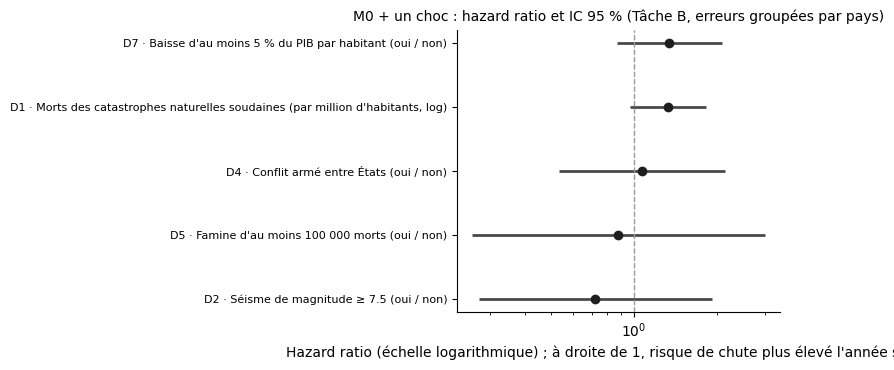

In [22]:
# ============================================================
# 6.4 Graphique : hazard ratio de chaque choc dans K2
# ============================================================
order = combined.sort_values("HR").index
fig, ax = plt.subplots(figsize=(8, 0.5 * len(order) + 1.3))
y = np.arange(len(order))
ax.hlines(y, combined.loc[order, "IC bas"], combined.loc[order, "IC haut"], color="#4a4a4a", linewidth=2)
ax.plot(combined.loc[order, "HR"], y, "o", color="#1f1f1f", markersize=6)
ax.axvline(1, color="#9a9a9a", linestyle="--", linewidth=1)
ax.set_yticks(y, [f"{CODE[v]} · {LABEL[v]}" for v in order], fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Hazard ratio (échelle logarithmique) ; à droite de 1, risque de chute plus élevé l'année suivante")
ax.set_title("M0 + un choc : hazard ratio et IC 95 % (Tâche B, erreurs groupées par pays)", fontsize=10)
ax.grid(axis="x", alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

In [23]:
# ============================================================
# 6.5 Variables non testables : estimations descriptives (hors règles de décision)
# ============================================================
REDUCED_TV = ["log_gdppc_lag1", "polity2_lag1"]
DESC_COLS = ["code", "unité", "parti-années", "chutes", "première année", "HR (M0 + variable)", "IC bas (M0 + variable)",
             "IC haut (M0 + variable)", "p (M0 + variable)", "HR (réduit)", "IC bas (réduit)", "IC haut (réduit)",
             "p (réduit)"]
desc_rows = []
for v in UNTESTABLE:
    dt = MT.dropna(subset=TF + [v])
    row = {"variable": v, "code": CODE[v], "unité": UNIT[v], "parti-années": len(dt), "chutes": int(dt["event"].sum()),
           "première année": int(dt["panel_year"].min()) if len(dt) else np.nan}
    if len(dt) and epp(dt, len(TF) + 1) >= MIN_EPP:
        row.update({f"{k} (M0 + variable)": x for k, x in hr_of(fit_cluster(dt, TF + [v]), v).items() if k != "coef"})
    dr = MT.dropna(subset=REDUCED_TV + [v])
    if len(dr) and epp(dr, len(REDUCED_TV) + 1) >= MIN_EPP:
        row.update({f"{k} (réduit)": x for k, x in hr_of(fit_cluster(dr, [v] + REDUCED_TV), v).items() if k != "coef"})
    desc_rows.append(row)
descriptive = pd.DataFrame(desc_rows, columns=["variable"] + DESC_COLS).set_index("variable")
if UNTESTABLE:
    display(Markdown("**Variables non testables** — estimations descriptives (M0 + la variable sur les années où elle "
                     "existe ; modèle réduit : la variable, le log du PIB par habitant et le score Polity2), erreurs "
                     "groupées par pays. Elles ne comptent pas dans la décision."))
    display(descriptive.round(3))
else:
    print("Toutes les variables sont testables.")

**Variables non testables** — estimations descriptives (M0 + la variable sur les années où elle existe ; modèle réduit : la variable, le log du PIB par habitant et le score Polity2), erreurs groupées par pays. Elles ne comptent pas dans la décision.

,code,unité,parti-années,chutes,première année,HR (M0 + variable),IC bas (M0 + variable),IC haut (M0 + variable),p (M0 + variable),HR (réduit),IC bas (réduit),IC haut (réduit),p (réduit)
variable,,,,,,,,,,,,,
battle_deaths,D3,×10,1598,95,1990,NaN,NaN,NaN,NaN,1.336,1.021,1.749,0.035
food_drop,D6,choc,2981,150,1963,0.854,0.509,1.433,0.55,0.861,0.497,1.491,0.593


## 7. Validation croisée (prédiction)

Le moteur d'évaluation est celui de `04_demographics.ipynb` (Section 7.1), limité à la Tâche B. Avant toute comparaison, il est vérifié : appliqué à M0 sur l'échantillon complet, il doit retrouver **exactement** les scores enregistrés par `03_ml_survival.ipynb` pour le modèle de Cox time-varying, pli par pli. Les 50 plis sont calculés en parallèle ; chaque calcul est déterministe.

In [24]:
# ============================================================
# 7.1 Moteur d'évaluation (Tâche B : hasard annuel)
# ============================================================
FOLDS = pd.read_csv(PROC / "ml_folds.csv", dtype={"row_id": str})
FOLDS_B = FOLDS.query("dataset == 'timevarying'").astype({"row_id": int})
WEIGHTS = np.round(np.linspace(0, 1, 11), 1)


def fold_assignment(df, rep):
    return FOLDS_B[FOLDS_B["repetition"] == rep].set_index("row_id").loc[df["row_id"], "fold"].to_numpy()


def inner_splits(train):
    return list(StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=RANDOM_STATE)
                .split(train, train["event"], train["Country"]))


def usable(train, feats):
    return [c for c in feats if train[c].var() > 0]     # une covariable constante ne peut pas être estimée


def ctv_probability(model, train, test, feats):
    """Probabilités annuelles du Cox time-varying, hasard de base constant par classe de durée (03, 4.2)."""
    risk = model.predict_partial_hazard(train[feats]).to_numpy()
    bins = train["time_bin_code"].to_numpy()
    h0 = pd.Series(train["event"].to_numpy()).groupby(bins).sum() / pd.Series(risk).groupby(bins).sum()
    h = h0.reindex(test["time_bin_code"].to_numpy()).to_numpy()
    assert not np.isnan(h).any(), "classe de durée absente du pli d'apprentissage"
    return 1 - np.exp(-h * model.predict_partial_hazard(test[feats]).to_numpy())


def blend_weight(train, f0, f1):
    """Poids du mélange choisi dans le pli d'apprentissage : perte logarithmique moyenne sur 3 plis internes."""
    score = np.zeros(len(WEIGHTS))
    for i_tr, i_va in inner_splits(train):
        tr, va = train.iloc[i_tr], train.iloc[i_va]
        p = [ctv_probability(fit_tv(tr, usable(tr, f)), tr, va, usable(tr, f)) for f in (f0, f1)]
        for j, w in enumerate(WEIGHTS):
            score[j] += log_loss(va["event"], (1 - w) * p[0] + w * p[1], labels=[0, 1])
    return float(WEIGHTS[int(np.argmin(score))])


def fold_B(df, assignment, rep, k, models, blends):
    warnings.filterwarnings("ignore")
    train, test = df[assignment != k], df[assignment == k]
    preds = {}
    for name, feats in models.items():
        f = usable(train, feats)
        preds[name] = (ctv_probability(fit_tv(train, f), train, test, f), np.nan)
    for name, base, other in blends:
        w = blend_weight(train, models[base], models[other])
        preds[name] = ((1 - w) * preds[base][0] + w * preds[other][0], w)
    return [{"model": name, "repetition": rep, "fold": k, "n_train": len(train), "n_test": len(test),
             "events_test": int(test["event"].sum()), "event_rate": float(test["event"].mean()),
             "roc_auc": roc_auc_score(test["event"], p), "pr_auc": average_precision_score(test["event"], p),
             "brier": brier_score_loss(test["event"], p), "log_loss": log_loss(test["event"], p, labels=[0, 1]),
             "weight": w} for name, (p, w) in preds.items()]


def evaluate(df, models, blends=(), comparison=""):
    """Les 50 plis (5 plis x 10 répétitions) en parallèle ; une ligne par modèle et par pli."""
    df = df.reset_index(drop=True)
    assignments = {rep: fold_assignment(df, rep) for rep in range(N_REPEATS)}
    out = Parallel(n_jobs=-1)(delayed(fold_B)(df, assignments[rep], rep, k, models, blends)
                              for rep in range(N_REPEATS) for k in range(N_FOLDS))
    return pd.DataFrame([r for rows in out for r in rows]).assign(comparison=comparison)

In [25]:
# ============================================================
# 7.2 Vérification : M0 sur l'échantillon complet retrouve les scores de 03_ml_survival.ipynb
# ============================================================
start = time.perf_counter()
check_B = evaluate(MT, {"M0": TF})
ref_B = pd.read_csv(PROC / "ml_results_taskB.csv").query("model == 'Cox time-varying'").set_index(["repetition", "fold"])
mine = check_B.set_index(["repetition", "fold"]).loc[ref_B.index]
gaps = {m: float((mine[m] - ref_B[m]).abs().max()) for m in ["roc_auc", "pr_auc", "brier", "log_loss"]}
assert max(gaps.values()) < 1e-9, gaps
display(Markdown(f"**Vérification réussie** ({time.perf_counter() - start:.0f} s). Sur l'échantillon complet, le moteur "
                 f"retrouve, pli par pli, les scores du Cox time-varying de `03_ml_survival.ipynb` (écart maximal "
                 f"{max(gaps.values()):.1e}) : ROC-AUC {ref_B['roc_auc'].mean():.3f} en moyenne sur 50 plis."))

**Vérification réussie** (3 s). Sur l'échantillon complet, le moteur retrouve, pli par pli, les scores du Cox time-varying de `03_ml_survival.ipynb` (écart maximal 9.7e-17) : ROC-AUC 0.673 en moyenne sur 50 plis.

In [26]:
# ============================================================
# 7.3 Comparaison sur l'échantillon commun
# ============================================================
start = time.perf_counter()
models = {"M0": TF, "K1": CAND, **{f"K2·{v}": TF + [v] for v in CAND}, **{f"K2t·{v}": TF + [v, "period"] for v in CAND}}
cv_B = evaluate(MC, models, [("K3", "M0", "K1")], comparison="chocs")
print(f"Validation croisée : {(time.perf_counter() - start) / 60:.1f} min ({cv_B['model'].nunique()} modèles x 50 plis)")

Validation croisée : 0.4 min (13 modèles x 50 plis)


In [27]:
# ============================================================
# 7.4 Scores moyens et tests appariés contre M0
# ============================================================
METRICS = {"roc_auc": ("ROC-AUC", True), "pr_auc": ("PR-AUC", True), "brier": ("Brier", False),
           "log_loss": ("Perte log.", False)}
PRIMARY = ("roc_auc", "log_loss")


def corrected_ttest(d, n_train, n_test):
    """Test t rééchantillonné corrigé (Nadeau & Bengio, 2003) pour des différences appariées."""
    J = len(d)
    t_stat = d.mean() / np.sqrt((1 / J + n_test / n_train) * d.var(ddof=1))
    return t_stat, 2 * stats.t.sf(abs(t_stat), df=J - 1)


def compare(cv):
    rows = []
    for comp, d in cv.groupby("comparison", sort=False):
        ref = d[d["model"] == "M0"].set_index(["repetition", "fold"])
        n_train, n_test = d["n_train"].mean(), d["n_test"].mean()
        for model in d["model"].unique():
            m = d[d["model"] == model].set_index(["repetition", "fold"])
            assert (m["n_test"] == ref["n_test"]).all(), f"{comp} / {model} : plis différents de M0"
            row = {"comparaison": comp, "modèle": model}
            for metric, (label, _) in METRICS.items():
                row[label] = f"{m[metric].mean():.3f} ± {m[metric].std():.3f}"
                if model != "M0":
                    diff = (m[metric] - ref[metric]).dropna()
                    _, p = corrected_ttest(diff, n_train, n_test)
                    row[f"{label} : écart"] = diff.mean()
                    row[f"{label} : p corrigée"] = p
            if model != "M0":
                dl, pl = METRICS[PRIMARY[0]][0], METRICS[PRIMARY[1]][0]
                better = row[f"{dl} : p corrigée"] < ALPHA and row[f"{dl} : écart"] > 0
                worse_prob = row[f"{pl} : p corrigée"] < ALPHA and row[f"{pl} : écart"] > 0
                worse = row[f"{dl} : p corrigée"] < ALPHA and row[f"{dl} : écart"] < 0
                row["verdict"] = ("meilleur que M0" if better and not worse_prob else
                                  "moins bon que M0" if worse else "pas de différence nette")
                if not np.isnan(m["weight"]).all():
                    row["poids moyen des chocs"] = m["weight"].mean()
            else:
                row["verdict"] = "référence"
            rows.append(row)
    return pd.DataFrame(rows)


tests = compare(cv_B)
display(Markdown(f"**Tâche B** (hasard annuel ; M0 sur l'échantillon complet de `03_ml_survival.ipynb` : ROC-AUC "
                 f"{ref_B['roc_auc'].mean():.3f} ± {ref_B['roc_auc'].std():.3f}) :"))
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(tests.round(4))

**Tâche B** (hasard annuel ; M0 sur l'échantillon complet de `03_ml_survival.ipynb` : ROC-AUC 0.673 ± 0.034) :

,comparaison,modèle,ROC-AUC,PR-AUC,Brier,Perte log.,verdict,ROC-AUC : écart,ROC-AUC : p corrigée,PR-AUC : écart,PR-AUC : p corrigée,Brier : écart,Brier : p corrigée,Perte log. : écart,Perte log. : p corrigée,poids moyen des chocs
0,chocs,M0,0.676 ± 0.035,0.120 ± 0.029,0.050 ± 0.002,0.199 ± 0.006,référence,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,chocs,K1,0.599 ± 0.034,0.085 ± 0.013,0.050 ± 0.002,0.206 ± 0.006,moins bon que M0,-0.0770,0.0000,-0.0355,0.0334,0.0006,0.0505,0.0068,0.0017,NaN
2,chocs,K2·disaster_deaths,0.678 ± 0.035,0.119 ± 0.021,0.050 ± 0.002,0.199 ± 0.007,pas de différence nette,0.0021,0.5552,-0.0014,0.8966,-0.0000,0.7053,-0.0002,0.6305,NaN
3,chocs,K2·quake,0.674 ± 0.035,0.121 ± 0.029,0.050 ± 0.002,0.199 ± 0.006,pas de différence nette,-0.0017,0.4743,0.0006,0.4397,0.0000,0.8130,0.0001,0.6253,NaN
4,chocs,K2·interstate_war,0.674 ± 0.036,0.119 ± 0.028,0.050 ± 0.002,0.199 ± 0.006,pas de différence nette,-0.0020,0.1699,-0.0014,0.3585,0.0000,0.1976,0.0003,0.1360,NaN
5,chocs,K2·famine,0.673 ± 0.036,0.120 ± 0.030,0.050 ± 0.002,0.199 ± 0.006,pas de différence nette,-0.0026,0.4141,-0.0003,0.8645,0.0000,0.2879,0.0004,0.4035,NaN
6,chocs,K2·recession,0.676 ± 0.034,0.118 ± 0.029,0.050 ± 0.002,0.199 ± 0.006,pas de différence nette,0.0006,0.8550,-0.0020,0.5656,0.0000,0.6327,0.0000,0.9282,NaN
7,chocs,K2t·disaster_deaths,0.677 ± 0.035,0.118 ± 0.021,0.050 ± 0.002,0.199 ± 0.007,pas de différence nette,0.0015,0.7296,-0.0025,0.8206,0.0000,0.9069,-0.0001,0.8376,NaN
8,chocs,K2t·quake,0.673 ± 0.035,0.119 ± 0.030,0.050 ± 0.002,0.199 ± 0.007,pas de différence nette,-0.0026,0.3389,-0.0012,0.7368,0.0001,0.3932,0.0003,0.4204,NaN
9,chocs,K2t·interstate_war,0.673 ± 0.036,0.117 ± 0.029,0.050 ± 0.002,0.199 ± 0.007,pas de différence nette,-0.0026,0.2640,-0.0030,0.4875,0.0001,0.0991,0.0004,0.1255,NaN


## 8. Décision et modèle final

Application des trois conditions de la Section 5 à chaque choc testé.

In [28]:
# ============================================================
# 8.1 Décision pour chaque choc
# ============================================================
holm_p = multipletests(combined.loc[CAND, "p"].to_numpy(), alpha=ALPHA, method="holm")[1]
tb = tests.set_index("modèle")
decision = pd.DataFrame(index=CAND)
decision["code"] = [CODE[v] for v in CAND]
decision["unité"] = [UNIT[v] for v in CAND]
for k in ("HR", "IC bas", "IC haut", "p"):
    decision[k] = combined.loc[CAND, k]
decision["p Holm"] = holm_p
decision["1. Holm < 0,05"] = holm_p < ALPHA
decision["écart ROC-AUC"] = [tb.loc[f"K2·{v}", "ROC-AUC : écart"] for v in CAND]
decision["p corrigée ROC-AUC"] = [tb.loc[f"K2·{v}", "ROC-AUC : p corrigée"] for v in CAND]
decision["2. ROC-AUC > M0"] = (decision["écart ROC-AUC"] > 0) & (decision["p corrigée ROC-AUC"] < ALPHA)
decision["HR (époque)"] = combined.loc[CAND, "époque HR"]
decision["p (époque)"] = combined.loc[CAND, "époque p"]
decision["3. époque"] = ((np.sign(combined.loc[CAND, "époque coef"]) == np.sign(combined.loc[CAND, "coef"]))
                         & (combined.loc[CAND, "époque p"] < ALPHA))
decision["retenue"] = decision["1. Holm < 0,05"] & decision["2. ROC-AUC > M0"] & decision["3. époque"]
KEPT = decision.index[decision["retenue"]].tolist()
display(decision.round(4))


def reasons(v):
    d = decision.loc[v]
    out = []
    if not d["1. Holm < 0,05"]:
        out.append(f"p ajustée de Holm {d['p Holm']:.3f}")
    if not d["2. ROC-AUC > M0"]:
        out.append(f"ROC-AUC {d['écart ROC-AUC']:+.4f} par rapport à M0 (p corrigée = {d['p corrigée ROC-AUC']:.3f})")
    if not d["3. époque"]:
        out.append(f"ne résiste pas au contrôle de l'époque (HR {d['HR (époque)']:.2f}, p = {d['p (époque)']:.3f})")
    return out


display(Markdown(
    f"**Chocs retenus** : {', '.join(f'`{v}`' for v in KEPT) if KEPT else 'aucun'}.\n\n"
    + "\n".join(f"- {CODE[v]} `{v}` ({LABEL[v]}) : " + ("retenu" if v in KEPT else "écarté — " + " ; ".join(reasons(v)))
                for v in CAND)))

,code,unité,HR,IC bas,IC haut,p,p Holm,"1. Holm < 0,05",écart ROC-AUC,p corrigée ROC-AUC,2. ROC-AUC > M0,HR (époque),p (époque),3. époque,retenue
disaster_deaths,D1,×10,1.3273,0.9637,1.8281,0.0830,0.4149,False,0.0021,0.5552,False,1.3265,0.0804,False,False
quake,D2,choc,0.7236,0.2732,1.9164,0.5150,1.0000,False,-0.0017,0.4743,False,0.7172,0.5034,False,False
interstate_war,D4,choc,1.0693,0.5348,2.1378,0.8497,1.0000,False,-0.0020,0.1699,False,1.0546,0.8782,False,False
famine,D5,choc,0.8776,0.2563,3.0056,0.8354,1.0000,False,-0.0026,0.4141,False,0.8841,0.8413,False,False
recession,D7,choc,1.3433,0.8666,2.0824,0.1869,0.7478,False,0.0006,0.8550,False,1.3436,0.1840,False,False


**Chocs retenus** : aucun.

- D1 `disaster_deaths` (Morts des catastrophes naturelles soudaines (par million d'habitants, log)) : écarté — p ajustée de Holm 0.415 ; ROC-AUC +0.0021 par rapport à M0 (p corrigée = 0.555) ; ne résiste pas au contrôle de l'époque (HR 1.33, p = 0.080)
- D2 `quake` (Séisme de magnitude ≥ 7.5 (oui / non)) : écarté — p ajustée de Holm 1.000 ; ROC-AUC -0.0017 par rapport à M0 (p corrigée = 0.474) ; ne résiste pas au contrôle de l'époque (HR 0.72, p = 0.503)
- D4 `interstate_war` (Conflit armé entre États (oui / non)) : écarté — p ajustée de Holm 1.000 ; ROC-AUC -0.0020 par rapport à M0 (p corrigée = 0.170) ; ne résiste pas au contrôle de l'époque (HR 1.05, p = 0.878)
- D5 `famine` (Famine d'au moins 100 000 morts (oui / non)) : écarté — p ajustée de Holm 1.000 ; ROC-AUC -0.0026 par rapport à M0 (p corrigée = 0.414) ; ne résiste pas au contrôle de l'époque (HR 0.88, p = 0.841)
- D7 `recession` (Baisse d'au moins 5 % du PIB par habitant (oui / non)) : écarté — p ajustée de Holm 0.748 ; ROC-AUC +0.0006 par rapport à M0 (p corrigée = 0.855) ; ne résiste pas au contrôle de l'époque (HR 1.34, p = 0.184)

In [29]:
# ============================================================
# 8.2 Modèle final F (seulement si au moins un choc est retenu)
# ============================================================
final = None
if KEPT:
    tF = MT.dropna(subset=TF + KEPT)
    epp_F = epp(tF, len(TF) + len(KEPT))
    if epp_F >= MIN_EPP:
        mF = fit_cluster(tF, TF + KEPT)
        cv_F = evaluate(tF, {"M0": TF, "F": TF + KEPT}, comparison="modèle final")
        cv_B = pd.concat([cv_B, cv_F], ignore_index=True)
        tests = compare(cv_B)
        final = {"variables": KEPT, "rows_tv": len(tF), "events_tv": int(tF["event"].sum()), "epp": epp_F,
                 "hazard_ratios": pd.DataFrame({v: hr_of(mF, v) for v in KEPT}).T}
        display(Markdown(f"**Modèle final F** : M0 + {', '.join(f'`{v}`' for v in KEPT)} ; {len(tF):,} parti-années, "
                         f"{int(tF['event'].sum())} chutes ({epp_F:.1f} chutes par paramètre)."))
        display(final["hazard_ratios"].round(3))
        display(tests[tests["comparaison"] == "modèle final"].round(4))
    else:
        display(Markdown(f"Le modèle final F n'est pas estimé : {epp_F:.1f} chutes par paramètre (minimum {MIN_EPP})."))
else:
    display(Markdown("**Aucun choc n'est retenu** : le modèle final F n'est pas estimé, et le modèle existant reste le "
                     "modèle de référence."))
cv_B.to_csv(PROC / "shocks_cv_taskB.csv", index=False)
print(f"data/processed/shocks_cv_taskB.csv ({len(cv_B)} lignes)")

**Aucun choc n'est retenu** : le modèle final F n'est pas estimé, et le modèle existant reste le modèle de référence.

data/processed/shocks_cv_taskB.csv (650 lignes)


## 9. Conclusion et limites

In [30]:
# ============================================================
# 9. Conclusion et limites (générées à partir des résultats)
# ============================================================
def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def lc(text):
    return text[:1].lower() + text[1:]


def direction(hr):
    return "plus élevé" if hr > 1 else "plus faible"


m0_auc = tb.loc["M0", "ROC-AUC"]
if KEPT:
    verdict_txt = (f"Selon les règles fixées en Section 5, {len(KEPT)} choc(s) sur {len(CAND)} change(nt) le risque de "
                   f"chute de façon mesurable : {', '.join(f'{CODE[v]} ({lc(LABEL[v])})' for v in KEPT)}.")
else:
    verdict_txt = (f"**Selon les règles fixées en Section 5, aucun des {len(CAND)} chocs testés ne change de façon "
                   "mesurable le risque de chute l'année suivante** : aucun ne remplit les trois conditions.")
sig_raw = decision.index[decision["p"] < ALPHA].tolist()
raw_txt = (f" Avant correction pour comparaisons multiples, {len(sig_raw)} choc(s) ont p < 0.05 dans K2 ("
           + ", ".join(f"{CODE[v]} : HR {decision.loc[v, 'HR']:.2f}, {fmt_p(decision.loc[v, 'p'])}" for v in sig_raw)
           + ")" if sig_raw else " Aucun choc n'a p < 0.05 dans K2, même avant correction")
raw_txt += f" ; la méthode de Holm porte sur {len(CAND)} chocs."
closest = decision["p"].idxmin()
c = decision.loc[closest]
raw_txt += (f" Le plus proche du seuil est {CODE[closest]} ({lc(LABEL[closest])}) : HR {c['HR']:.2f} "
            f"(IC 95 % {c['IC bas']:.2f}-{c['IC haut']:.2f}), {fmt_p(c['p'])} avec des erreurs groupées par pays, "
            f"{fmt_p(combined.loc[closest, 'p (non groupée)'])} sans les grouper (comme dans `final_panel.ipynb`).")

near_txt = ""
for v in CAND:
    d = decision.loc[v]
    failed = [n for n, ok in ((1, d["1. Holm < 0,05"]), (2, d["2. ROC-AUC > M0"]), (3, d["3. époque"])) if not ok]
    if v in KEPT or len(failed) != 1:
        continue
    what = {1: f"son effet ne reste pas significatif après la correction de Holm (p ajustée = {d['p Holm']:.3f})",
            2: (f"il n'améliore pas nettement la ROC-AUC en validation croisée ({d['écart ROC-AUC']:+.4f}, p corrigée = "
                f"{d['p corrigée ROC-AUC']:.3f})"),
            3: f"son effet ne résiste pas au contrôle de l'époque ({fmt_p(d['p (époque)'])})"}[failed[0]]
    near_txt += (f"\n\n**Presque retenu : {CODE[v]} ({lc(LABEL[v])}).** Il remplit deux des trois conditions "
                 f"(HR {d['HR']:.2f}, IC 95 % {d['IC bas']:.2f}-{d['IC haut']:.2f}), mais {what}. Après ce choc, le "
                 f"risque de chute est {direction(d['HR'])} l'année suivante, à valeurs égales des facteurs du modèle "
                 "existant : c'est une association, pas un effet.")

k1_auc, k1_d, k1_p, k1_v = tb.loc["K1", "ROC-AUC"], tb.loc["K1", "ROC-AUC : écart"], tb.loc["K1", "ROC-AUC : p corrigée"], tb.loc["K1", "verdict"]
k3_auc, k3_v, k3_w = tb.loc["K3", "ROC-AUC"], tb.loc["K3", "verdict"], tb.loc["K3", "poids moyen des chocs"]
best = decision["écart ROC-AUC"].idxmax()
block_txt = (f"**Prédiction** — sur l'échantillon commun ({sample_info['rows_tv']:,} parti-années, "
             f"{sample_info['events_tv']} chutes), M0 atteint une ROC-AUC de {m0_auc}. Seuls, les chocs (K1) obtiennent "
             f"{k1_auc} ({k1_d:+.3f}, {fmt_p(k1_p)} ; {k1_v}). Mélangés à M0 (K3), avec un poids moyen de {k3_w:.2f} "
             f"pour les chocs, ils obtiennent {k3_auc} ({k3_v}). Le choc qui améliore le plus M0 est {CODE[best]} "
             f"({decision.loc[best, 'écart ROC-AUC']:+.4f}, p corrigée = {decision.loc[best, 'p corrigée ROC-AUC']:.3f}).")

untestable_txt = ""
if UNTESTABLE:
    def describe(v):
        r = descriptive.loc[v]
        parts = []
        if pd.notna(r["HR (M0 + variable)"]):
            parts.append(f"HR {r['HR (M0 + variable)']:.2f} avec M0 ({fmt_p(r['p (M0 + variable)'])})")
        if pd.notna(r["HR (réduit)"]):
            parts.append(f"HR {r['HR (réduit)']:.2f} dans le modèle réduit ({fmt_p(r['p (réduit)'])})")
        return f"{CODE[v]} : " + (" ; ".join(parts) if parts else "trop peu de chutes pour un modèle")
    untestable_txt = ("**Variables non testables** : " + "; ".join(
        f"{CODE[v]} ({lc(LABEL[v])} : {dropped[v] if v in dropped else removed_reason[v]})" for v in UNTESTABLE)
        + ". À titre descriptif seulement (Section 6.5) : " + " ; ".join(describe(v) for v in UNTESTABLE) + ".")

display(Markdown("### 9.1 Réponse\n\n" + verdict_txt + raw_txt + near_txt + "\n\n" + block_txt
                 + ("\n\n" + untestable_txt if untestable_txt else "")))

exposed = coverage.loc[CAND, "parti-années avec choc"]
rare = [v for v in CAND if exposed[v] < 100]
historic = float((nat.loc[nat["year"].between(1946, 2023), "Historic"] == "Yes").mean())
limits = [
    "**Causalité inverse** : une famine, une guerre ou une récession peut venir du régime lui-même (politique "
    "agricole, répression, choix économiques) ou de la crise qui le fait tomber ; le décalage d'un an ne l'exclut pas. "
    "Seul le grand séisme (D2) est un choc vraiment extérieur au régime.",
    f"**Recensement inégal** : {historic:.0%} des catastrophes d'EM-DAT retenues entre 1946 et 2023 sont antérieures à "
    "2000, période où EM-DAT signale un recensement moins complet ; les catastrophes et leurs victimes sont aussi plus "
    "souvent passées sous silence dans les régimes fermés. Le contrôle de l'époque ne corrige qu'une tendance commune.",
    "**Chutes de la même année** : un choc qui renverse un régime dans l'année même (invasion, comme en Irak en 2003, ou "
    "défaite militaire immédiate) n'est pas vu, puisque chaque chute est reliée aux chocs de l'année précédente.",
    "**Associations, pas causes** : les hazard ratios décrivent un risque de chute plus ou moins élevé après un choc, "
    "à valeurs égales des facteurs du modèle existant.",
    ("**Peu d'événements** : " + ", ".join(f"{CODE[v]} ne touche que {exposed[v]} parti-années" for v in rare)
     + " ; leurs effets sont estimés avec une grande imprécision. " if rare else "**Peu de chutes** : ")
    + f"Les modèles restent juste au-dessus de {MIN_EPP} chutes par paramètre : un effet modeste peut passer inaperçu.",
    "**Attribution des événements** : un événement est attribué à l'État qui existait à sa date ; dans un pays alors "
    "divisé (Viêt Nam, Allemagne), un événement meurtrier sans lieu précis rend la valeur manquante ; les territoires "
    "dépendants ne comptent pour aucun parti. Les morts au combat sont répartis entre les pays où se situe le conflit.",
    (f"**Deux sources pour les morts au combat** : PRIO jusqu'en 1988, UCDP ensuite (corrélation de {concordance:.2f} "
     "conflit par conflit sur 1989-2008)." if SPLICE else
     f"**Morts au combat depuis 1989 seulement** : PRIO et UCDP ne concordent pas assez (corrélation de "
     f"{concordance:.2f})."),
    "**Séries économiques** : FAOSTAT ne publie les indices de production que pour les pays actuels, depuis leur "
    "création ; Maddison s'arrête en 2022 et interpole certaines années anciennes, ce qui peut masquer des récessions.",
]
display(Markdown("### 9.2 Limites\n\n" + "\n".join(f"* {l}" for l in limits)))
display(Markdown("**Conséquence pour le site.** " + (
    "Aucun choc n'étant retenu, le modèle de la simulation ne change pas. " if not KEPT else
    "Les chocs retenus décrivent ce qui arrive au pays, pas des choix d'un parti : ils ne deviennent pas des "
    "paramètres de la simulation. ") + "Le résultat est présenté sur la page Analyse comme un test de robustesse."))

### 9.1 Réponse

**Selon les règles fixées en Section 5, aucun des 5 chocs testés ne change de façon mesurable le risque de chute l'année suivante** : aucun ne remplit les trois conditions. Aucun choc n'a p < 0.05 dans K2, même avant correction ; la méthode de Holm porte sur 5 chocs. Le plus proche du seuil est D1 (morts des catastrophes naturelles soudaines (par million d'habitants, log)) : HR 1.33 (IC 95 % 0.96-1.83), p = 0.083 avec des erreurs groupées par pays, p = 0.060 sans les grouper (comme dans `final_panel.ipynb`).

**Prédiction** — sur l'échantillon commun (3,563 parti-années, 190 chutes), M0 atteint une ROC-AUC de 0.676 ± 0.035. Seuls, les chocs (K1) obtiennent 0.599 ± 0.034 (-0.077, p < 0.001 ; moins bon que M0). Mélangés à M0 (K3), avec un poids moyen de 0.22 pour les chocs, ils obtiennent 0.671 ± 0.032 (pas de différence nette). Le choc qui améliore le plus M0 est D1 (+0.0021, p corrigée = 0.555).

**Variables non testables** : D3 (morts au combat dans le pays (par million d'habitants, log) : 95 chutes); D6 (baisse d'au moins 10 % de la production alimentaire par habitant (oui / non) : échantillon commun : 148 chutes, soit 9.9 chutes par paramètre pour le plus grand modèle prévu (15 paramètres)). À titre descriptif seulement (Section 6.5) : D3 : HR 1.34 dans le modèle réduit (p = 0.035) ; D6 : HR 0.85 avec M0 (p = 0.550) ; HR 0.86 dans le modèle réduit (p = 0.593).

### 9.2 Limites

* **Causalité inverse** : une famine, une guerre ou une récession peut venir du régime lui-même (politique agricole, répression, choix économiques) ou de la crise qui le fait tomber ; le décalage d'un an ne l'exclut pas. Seul le grand séisme (D2) est un choc vraiment extérieur au régime.
* **Recensement inégal** : 39% des catastrophes d'EM-DAT retenues entre 1946 et 2023 sont antérieures à 2000, période où EM-DAT signale un recensement moins complet ; les catastrophes et leurs victimes sont aussi plus souvent passées sous silence dans les régimes fermés. Le contrôle de l'époque ne corrige qu'une tendance commune.
* **Chutes de la même année** : un choc qui renverse un régime dans l'année même (invasion, comme en Irak en 2003, ou défaite militaire immédiate) n'est pas vu, puisque chaque chute est reliée aux chocs de l'année précédente.
* **Associations, pas causes** : les hazard ratios décrivent un risque de chute plus ou moins élevé après un choc, à valeurs égales des facteurs du modèle existant.
* **Peu d'événements** : D2 ne touche que 64 parti-années, D5 ne touche que 61 parti-années ; leurs effets sont estimés avec une grande imprécision. Les modèles restent juste au-dessus de 10 chutes par paramètre : un effet modeste peut passer inaperçu.
* **Attribution des événements** : un événement est attribué à l'État qui existait à sa date ; dans un pays alors divisé (Viêt Nam, Allemagne), un événement meurtrier sans lieu précis rend la valeur manquante ; les territoires dépendants ne comptent pour aucun parti. Les morts au combat sont répartis entre les pays où se situe le conflit.
* **Morts au combat depuis 1989 seulement** : PRIO et UCDP ne concordent pas assez (corrélation de 0.79).
* **Séries économiques** : FAOSTAT ne publie les indices de production que pour les pays actuels, depuis leur création ; Maddison s'arrête en 2022 et interpole certaines années anciennes, ce qui peut masquer des récessions.

**Conséquence pour le site.** Aucun choc n'étant retenu, le modèle de la simulation ne change pas. Le résultat est présenté sur la page Analyse comme un test de robustesse.

## 10. Export des résultats

Les résultats sont écrits dans `data/processed/site_results_shocks.json`, avec la même structure que les autres exports (tableaux au format « split » de pandas). Le site les lit (page Analyse, carte « Les chocs font-ils tomber les partis ? ») ; ses textes en français, en anglais et en arabe sont construits à partir de ces chiffres par `src/site_text.py` (`shocks_texts`). L'export ne contient que des tableaux de résultats : aucune valeur pays-année.

In [31]:
# ============================================================
# 10. Export (data/processed/site_results_shocks.json)
# ============================================================
from site_text import shocks_texts      # textes du site en français, anglais et arabe


def metric_summary(cv):
    out = []
    for (comp, model), d in cv.groupby(["comparison", "model"], sort=False):
        out.append({"comparison": comp, "model": model,
                    **{m: {"mean": float(d[m].mean()), "sd": float(d[m].std())} for m in METRICS}})
    return out


site_shocks = {
    "source": "notebooks/05_shocks.ipynb",
    "created": date.today().isoformat(),
    "protocol": {"folds": N_FOLDS, "repeats": N_REPEATS, "evaluations": N_FOLDS * N_REPEATS, "grouped_by": "Country",
                 "folds_file": "data/processed/ml_folds.csv", "inner_folds": N_INNER, "blend_weights": list(WEIGHTS),
                 "min_falls": MIN_FALLS, "min_events_per_parameter": MIN_EPP, "largest_model_parameters": LARGEST,
                 "alpha": ALPHA, "multiple_testing": "holm", "test": "test t rééchantillonné corrigé (Nadeau & Bengio, 2003)",
                 "standard_errors": "groupées par pays", "lag_years": 1, "period": "(année - 2000) / 10",
                 "quake_min_magnitude": QUAKE_MIN, "food_drop": FOOD_DROP, "recession": RECESSION,
                 "concordance_min": CONCORDANCE_MIN, "reduced_tv_model": REDUCED_TV, "rules_fixed": "2026-10-16"},
    "sources": [{"file": name, **info} for name, info in log.items()]
               + [{"file": "UcdpPrioConflict_v26_1.csv", "version": "26.1"}, {"file": "mpd2023_web.xlsx", "version": "2023"},
                  {"file": "WPP2024_PopulationByAge5GroupSex_Medium.csv.gz", "version": "2024"}],
    "totals": {"rows_tv": len(tv), "events_tv": int(tv["event"].sum())},
    "candidates": candidates_table,
    "coverage": coverage.reset_index(),
    "screening": {"dropped": dropped, "removed_for_sample": removed_for_sample, "removed_reason": removed_reason,
                  "retained": CAND},
    "sample": sample_info,
    "splice": SPLICE_INFO,
    "correlations": corr_table.reset_index(),
    "vif": vif_table.rename("VIF").reset_index(),
    "events_per_parameter": planned,
    "coef_check_max_gap": COEF_GAP,
    "models": {"combined": combined.reset_index(), "block": block_models, "descriptive": descriptive.reset_index()},
    "cv": {"task_b": {"metrics": metric_summary(cv_B), "tests": tests},
           "full_sample_m0": {"roc_auc": {"mean": float(ref_B["roc_auc"].mean()), "sd": float(ref_B["roc_auc"].std())}}},
    "decision": decision.reset_index().rename(columns={"index": "variable"}),
    "kept": KEPT,
    "final_model": final,
}
site_shocks["texts"] = shocks_texts(site_shocks)
size_kb = write_json(PROC / "site_results_shocks.json", site_shocks)
print(f"data/processed/site_results_shocks.json : {size_kb:.0f} Ko")

data/processed/site_results_shocks.json : 43 Ko


## 11. Références

**Données.**
- **Bolt, J., & van Zanden, J. L.** (2024). Maddison-style estimates of the evolution of the world economy: A new 2023 update. *Journal of Economic Surveys*, 39(2), 631–671. https://doi.org/10.1111/joes.12618
- **CRED / UCLouvain** (2026). *EM-DAT: The Emergency Events Database*, archive validée v2. https://doi.org/10.14428/DVN/I0LTPH ; Delforge, D., et al. (2025). EM-DAT: the Emergency Events Database. *International Journal of Disaster Risk Reduction*.
- **Davies, S., Pettersson, T., & Öberg, M.** (2026). Organized violence 1989–2025, and violent political protests. *Journal of Peace Research*, 63(4), 705–723 ; *UCDP Battle-Related Deaths Dataset* et *UCDP/PRIO Armed Conflict Dataset*, version 26.1. https://ucdp.uu.se/downloads/
- **FAO** (2026). *FAOSTAT : Production Indices*. https://www.fao.org/faostat/
- **Gleditsch, N. P., Wallensteen, P., Eriksson, M., Sollenberg, M., & Strand, H.** (2002). Armed Conflict 1946–2001: A New Dataset. *Journal of Peace Research*, 39(5), 615–637.
- **Lacina, B., & Gleditsch, N. P.** (2005). Monitoring Trends in Global Combat: A New Dataset of Battle Deaths. *European Journal of Population*, 21(2–3), 145–166 ; PRIO (2009), *Battle Deaths Dataset*, version 3.1.
- **NOAA National Centers for Environmental Information** (2026). *NCEI/WDS Global Significant Earthquake Database*. https://doi.org/10.7289/V5TD9V7K
- **United Nations, Department of Economic and Social Affairs, Population Division** (2024). *World Population Prospects 2024*.
- **World Peace Foundation** (2025). *Historic Famines* (WPF Famine Dataset), traité par Our World in Data. https://ourworldindata.org/famines

**Méthodes et concepts.**
- **Burke, P. J., & Leigh, A.** (2010). Do Output Contractions Trigger Democratic Change? *American Economic Journal: Macroeconomics*, 2(4), 124–157.
- **Flores, A. Q., & Smith, A.** (2013). Leader Survival and Natural Disasters. *British Journal of Political Science*, 43(4), 821–843.
- **Holm, S.** (1979). A Simple Sequentially Rejective Multiple Test Procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.
- **Nadeau, C., & Bengio, Y.** (2003). Inference for the Generalization Error. *Machine Learning*, 52(3), 239–281.
- **Sen, A.** (1981). *Poverty and Famines: An Essay on Entitlement and Deprivation*. Oxford University Press.